In [1]:
import numpy as np
import seaborn as sns
import pandas as pd
import logomaker
import sys
PATH_TO_PREDICTOR_HOME = "../.."
sys.path.append(PATH_TO_PREDICTOR_HOME)
METHOD = "hmm_pomegranate"


In [2]:
import numpy as np

In [3]:
DATA_PATH_BASE = 'G:/My Drive/Work/ITMO/data'
DATA_PATH = f'{DATA_PATH_BASE}/amino_acid_properties/per_length_per_kfold_split/' # work laptop
# DATA_PATH = 'D:/Google Drive/Work/ITMO/data/length_dependent_hmm/per_length_per_kfold_split/' # windows
# DATA_PATH = '/home/denklewer/Data/length_dependent_hmm/' #ubuntu
TARGET_PATH_TO_RESULTS = "experiment_results/properites_training/"

In [4]:
from data_reading_methods import get_available_alleles, read_data

ALLELES = get_available_alleles(DATA_PATH)
ALLELES = [ 'HLA-DRB1*01:01']
ALLELES

['HLA-DRB1*01:01']

In [5]:



per_allele_per_kfold_per_length_binders_train = read_data(DATA_PATH, ALLELES, "train", "binders")
per_allele_per_kfold_per_length_binders_test = read_data(DATA_PATH, ALLELES, "test", "binders")


In [6]:
ALLELES

['HLA-DRB1*01:01']

In [7]:
def make_logo_for_data(binders_array, name):
    sns.set_theme(style="white")
    matrix = logomaker.alignment_to_matrix(binders_array)
    info_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='information')
    prob_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='probability')
    ww_logo = logomaker.Logo(info_matrix, font_name='Arial Rounded MT Bold', flip_below=True)
    ww_logo.ax.set_title(f"{name}, {len(binders_array)}")

In [8]:
# combination_size = len(ALLELES)
# ALLELES = sorted(['HLA-A*01:01', 'HLA-A*03:01', 'HLA-A*02:01'
#                   ])
ALLELES = sorted([   'HLA-DRB1*01:01'
                   # 'HLA-A*11:01',
                   #  
#                    #'HLA-A*02:01', , 'HLA-A*24:02'
                ])

# ALLELES = sorted(['HLA-DRB1*01:01', 'HLA-DRB3*01:01'])
# ALLELES = sorted(['HLA-DRB1*01:01'])

combination_size = 1
TOTAL_SPLITS = 5
NUM_RUNS = 5
USE_WEIGHTS = True
# TARGET_LENGTHS= [13, 14, 15, 16, 17, 18]

# TARGET_LENGTHS= [15, 17]
# TARGET_LENGTHS= [9,  11]
TARGET_LENGTHS= [15, 18]
check_peptides = False

# Motif check

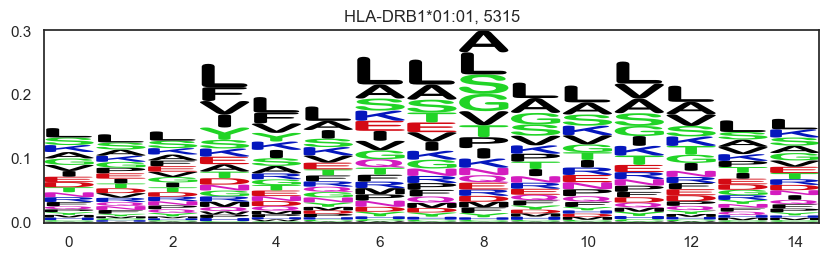

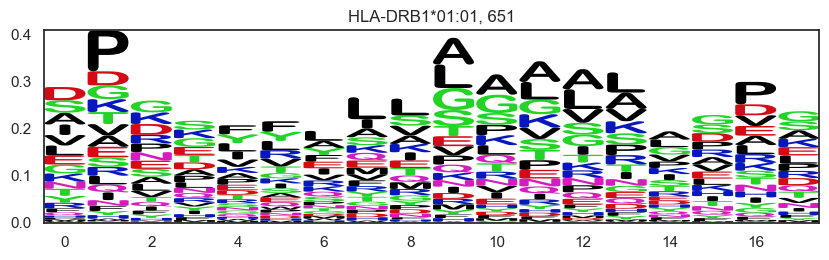

In [9]:
target_allele = ALLELES[0]
for target_allele in ALLELES:
    for target_length in TARGET_LENGTHS:
        peptides = per_allele_per_kfold_per_length_binders_train[target_allele][0][target_length]
        make_logo_for_data(peptides, target_allele)

# Prepare properties

In [10]:
from protlearn.features import aaindex1

In [11]:
amino_acids = list('ACDEFGHIKLMNPQRSTVWY')
prop_values, prop_names = aaindex1(amino_acids, standardize='zscore')
aa_prop_index = pd.DataFrame(prop_values, columns=prop_names, index=amino_acids).dropna(axis='columns')

In [12]:
all_properties = list(aa_prop_index.columns)

selected_properties = all_properties


transform_dicts = list()

# We want to normalize values of properties
for property_name in selected_properties:
    transform_dicts.append(aa_prop_index[property_name].to_dict())

In [13]:
props_file = "not_correlated_properties.csv"
new_prop_index = pd.read_csv(props_file, index_col=0)

In [14]:

transform_dicts = list()

# We want to normalize values of properties

selected_properties = new_prop_index.columns
for property_name in selected_properties:
    transform_dicts.append(new_prop_index[property_name].to_dict())

In [15]:
new_prop_index

,new_prop_0,new_prop_1,new_prop_2,new_prop_3,new_prop_4,new_prop_5,new_prop_6,new_prop_7,new_prop_8,new_prop_9,...,new_prop_63,new_prop_64,new_prop_65,new_prop_66,new_prop_67,new_prop_68,new_prop_69,new_prop_70,new_prop_71,new_prop_72
A,-1.429296,-0.274430,-1.256097,1.223667,-0.067528,1.239569,-1.358514,-0.285351,0.434652,-0.547908,...,-0.563912,1.158412,1.370698,-0.402931,0.076632,0.635567,-0.118064,-0.591551,0.206572,-1.209077
C,-0.165978,0.840132,1.087031,0.676639,-0.303310,-0.900565,-0.850652,1.051578,-0.427133,-0.766460,...,1.070859,-0.484250,-1.779157,1.022202,-0.513179,1.673172,-2.479967,0.026079,-0.614947,0.503404
D,-0.478462,-1.061168,0.525950,0.015357,-0.924675,-0.366156,-0.395932,-0.294963,1.766860,-0.589097,...,-0.466376,-0.005830,0.673031,1.435701,0.506343,-1.102858,-0.630299,1.565869,-1.919359,-0.256526
E,0.107572,-0.768375,-1.102205,-0.093201,-0.918985,0.920453,0.085466,0.603056,2.625648,-0.855890,...,-0.802705,1.792886,0.765549,-0.655170,-0.195933,0.455644,0.511617,0.628942,-0.648784,-1.250244
F,0.633390,1.050927,-0.419086,-1.068883,1.705486,0.379376,0.995988,0.759017,-0.381880,2.101111,...,0.985004,0.290810,-0.037837,0.985941,-1.051481,-0.324255,0.713757,-0.017638,0.723445,-0.210342
G,-1.732990,-0.323625,1.505401,1.265135,-0.461312,-1.633190,-1.919517,-0.201788,-0.593777,-0.266577,...,-0.268116,-1.658701,1.641083,-2.086082,0.804745,-1.396476,-1.322082,0.141732,-1.093035,0.463100
H,0.740862,0.247579,-0.317551,-0.743211,-0.586506,-0.255813,0.530971,-1.573553,-0.408477,-0.154767,...,0.389025,0.547614,0.312213,0.845141,-0.448381,-0.023382,0.435072,-0.908554,-0.812695,0.579846
I,-0.113714,0.963791,-1.133665,-0.622328,1.248841,0.347415,0.046852,1.778647,-0.581699,1.354926,...,0.586944,0.006574,-0.146338,-1.509504,-0.530900,-0.242521,-0.477215,0.328777,1.689327,0.581464
K,1.109553,-1.290673,0.326200,0.105193,-1.026328,0.339223,0.555222,-0.808479,-0.344986,-0.761515,...,-0.733175,0.730541,-1.373418,-0.360891,0.175912,0.677848,-0.206652,-0.405093,0.927217,-0.562186
L,-0.229879,1.354582,-1.091962,0.046457,1.341374,1.212728,0.064782,0.395401,-0.495099,-0.104469,...,0.688390,0.892295,-0.192075,-0.675164,-0.474695,0.285157,0.713921,-1.235779,1.593334,-0.380958


In [16]:
new_prop_index.describe()

,new_prop_0,new_prop_1,new_prop_2,new_prop_3,new_prop_4,new_prop_5,new_prop_6,new_prop_7,new_prop_8,new_prop_9,...,new_prop_63,new_prop_64,new_prop_65,new_prop_66,new_prop_67,new_prop_68,new_prop_69,new_prop_70,new_prop_71,new_prop_72
count,2.000000e+01,2.000000e+01,2.000000e+01,2.000000e+01,2.000000e+01,2.000000e+01,2.000000e+01,2.000000e+01,2.000000e+01,2.000000e+01,...,2.000000e+01,2.000000e+01,2.000000e+01,2.000000e+01,2.000000e+01,2.000000e+01,2.000000e+01,2.000000e+01,2.000000e+01,2.000000e+01
mean,-4.996004e-17,-1.887379e-16,-2.220446e-16,-6.661338e-17,-2.220446e-17,-1.637579e-16,9.992007e-17,5.551115e-17,-1.665335e-17,-2.220446e-17,...,4.440892e-17,1.110223e-17,1.276756e-16,9.436896e-16,2.775558e-18,-4.662937e-16,7.216450e-17,-1.249001e-17,1.174061e-15,-4.059253e-17
std,9.082645e-01,8.998910e-01,9.221338e-01,8.740392e-01,9.198910e-01,9.126532e-01,9.696932e-01,8.090729e-01,8.406296e-01,8.273272e-01,...,9.038278e-01,9.724404e-01,9.737854e-01,1.012836e+00,9.246154e-01,9.186162e-01,9.719374e-01,9.212962e-01,9.601512e-01,9.146063e-01
min,-1.732990e+00,-1.290673e+00,-1.506356e+00,-1.955006e+00,-1.026328e+00,-1.816294e+00,-1.919517e+00,-1.573553e+00,-6.609474e-01,-8.558895e-01,...,-2.048168e+00,-1.670952e+00,-1.779157e+00,-2.086082e+00,-1.051481e+00,-1.733972e+00,-2.479967e+00,-1.235779e+00,-1.919359e+00,-1.452238e+00
25%,-7.339691e-01,-7.701813e-01,-9.948576e-01,-5.540132e-01,-7.378047e-01,-6.851728e-01,-5.106230e-01,-4.559903e-01,-4.620057e-01,-5.582051e-01,...,-7.344437e-01,-7.053831e-01,-4.478673e-01,-4.714962e-01,-4.843162e-01,-2.907302e-01,-4.373365e-01,-4.794530e-01,-6.234060e-01,-6.599867e-01
50%,-1.390924e-01,-2.182919e-01,1.748943e-01,-2.840311e-03,-3.066432e-01,2.281881e-01,5.581713e-02,-1.383196e-03,-3.768960e-01,-2.640780e-01,...,-1.110336e-01,3.721905e-04,-9.208750e-02,-7.606298e-02,-1.712027e-01,2.034412e-03,-1.961366e-02,-1.365431e-01,-1.147644e-02,3.543443e-02
75%,6.626141e-01,8.710464e-01,6.843334e-01,6.893974e-01,6.115598e-01,5.065861e-01,5.370340e-01,4.894758e-01,2.767848e-01,3.085825e-01,...,6.144703e-01,6.845867e-01,6.961603e-01,8.803409e-01,1.545800e-01,5.006246e-01,5.571651e-01,2.191665e-01,5.621243e-01,5.802504e-01
max,1.538281e+00,1.416425e+00,1.505401e+00,1.265135e+00,1.705486e+00,1.396234e+00,2.071846e+00,1.778647e+00,2.625648e+00,2.101111e+00,...,1.467631e+00,1.792886e+00,1.641083e+00,1.435701e+00,3.442434e+00,1.673172e+00,2.305134e+00,2.745137e+00,1.689327e+00,1.586752e+00


# Transform data

In [17]:
dfs = list()
for allele_name, per_kfold_per_length in per_allele_per_kfold_per_length_binders_train.items():
    for split_num, per_length_data in per_kfold_per_length.items():
        for target_length, data in per_length_data.items():
            peptides = data
            df = pd.DataFrame({"peptide":data, "length":target_length, "allele": allele_name, "split":split_num})
            dfs.append(df)
    

In [18]:
peptide_df = pd.concat(dfs)

peptide_df = peptide_df[peptide_df['length'].isin(TARGET_LENGTHS)]
peptide_df = peptide_df[peptide_df['split'].isin([0])]
peptide_df = peptide_df.reset_index(drop=True)

In [19]:
peptide_df.head()

,peptide,length,allele,split
0,NDKFTVFEGAFNKAI,15,HLA-DRB1*01:01,0
1,VRDEVQLALHKMKSS,15,HLA-DRB1*01:01,0
2,IKIFHGLKSTDVAKT,15,HLA-DRB1*01:01,0
3,CPKLVKQNTLKLATG,15,HLA-DRB1*01:01,0
4,VLSFELLNAPATVCG,15,HLA-DRB1*01:01,0


In [20]:
import numpy as np

In [21]:
list_peptides = [list(peptide) for peptide in peptide_df.peptide.values]
converted_peptides = [np.array([[transform_dict[aa] for transform_dict in transform_dicts] for aa in  peptide]) for peptide in list_peptides]

In [22]:
converted_peptides[0].shape

(15, 73)

In [23]:
converted_peptides[-1].shape

(18, 73)

In [24]:
peptide_df.iloc[0].peptide

'NDKFTVFEGAFNKAI'

In [25]:
pd.DataFrame(converted_peptides[0].T)

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
0,-0.164471,-0.478462,1.109553,0.633390,-0.781533,-0.718115,0.633390,0.107572,-1.732990,-1.429296,0.633390,-0.164471,1.109553,-1.429296,-0.113714
1,-1.180408,-1.061168,-1.290673,1.050927,-0.450244,1.195307,1.050927,-0.768375,-0.323625,-0.274430,1.050927,-1.180408,-1.290673,-0.274430,0.963791
2,0.822620,0.525950,0.326200,-0.419086,0.090254,-1.506356,-0.419086,-1.102205,1.505401,-1.256097,-0.419086,0.822620,0.326200,-1.256097,-1.133665
3,-0.021038,0.015357,0.105193,-1.068883,0.727673,0.347113,-1.068883,-0.093201,1.265135,1.223667,-1.068883,-0.021038,0.105193,1.223667,-0.622328
4,-0.818047,-0.924675,-1.026328,1.705486,-0.309976,0.653603,1.705486,-0.918985,-0.461312,-0.067528,1.705486,-0.818047,-1.026328,-0.067528,1.248841
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
68,0.224476,-1.102858,0.677848,-0.324255,0.342597,0.027451,-0.324255,0.455644,-1.396476,0.635567,-0.324255,0.224476,0.677848,0.635567,-0.242521
69,-0.770047,-0.630299,-0.206652,0.713757,0.078837,-0.218856,0.713757,0.511617,-1.322082,-0.118064,0.713757,-0.770047,-0.206652,-0.118064,-0.477215
70,-0.144505,1.565869,-0.405093,-0.017638,-0.654887,0.182630,-0.017638,0.628942,0.141732,-0.591551,-0.017638,-0.144505,-0.405093,-0.591551,0.328777
71,-1.211052,-1.919359,0.927217,0.723445,-0.042944,1.352894,0.723445,-0.648784,-1.093035,0.206572,0.723445,-1.211052,0.927217,0.206572,1.689327


# DTW 

In [26]:
from matplotlib.patches import ConnectionPatch
import matplotlib.pyplot as plt
import numpy as np
import scipy.spatial.distance as dist


## Dynamic programming function

In [27]:
def dp(dist_mat):
    """
    Find minimum-cost path through matrix `dist_mat` using dynamic programming.

    The cost of a path is defined as the sum of the matrix entries on that
    path. See the following for details of the algorithm:

    - http://en.wikipedia.org/wiki/Dynamic_time_warping
    - https://www.ee.columbia.edu/~dpwe/resources/matlab/dtw/dp.m

    The notation in the first reference was followed, while Dan Ellis's code
    (second reference) was used to check for correctness. Returns a list of
    path indices and the cost matrix.
    """

    N, M = dist_mat.shape
    
    # Initialize the cost matrix
    cost_mat = np.zeros((N + 1, M + 1))
    for i in range(1, N + 1):
        cost_mat[i, 0] = np.inf
    for i in range(1, M + 1):
        cost_mat[0, i] = np.inf

    # Fill the cost matrix while keeping traceback information
    traceback_mat = np.zeros((N, M))
    for i in range(N):
        for j in range(M):
            penalty = [
                cost_mat[i, j],      # match (0)
                cost_mat[i, j + 1],  # insertion (1)
                cost_mat[i + 1, j]]  # deletion (2)
            i_penalty = np.argmin(penalty)
            cost_mat[i + 1, j + 1] = dist_mat[i, j] + penalty[i_penalty]
            traceback_mat[i, j] = i_penalty


    # Traceback from bottom right
    i = N - 1
    j = M - 1
    path = [(i, j)]
    while i > 0 or j > 0:
        tb_type = traceback_mat[i, j]
        if tb_type == 0:
            # Match
            i = i - 1
            j = j - 1
        elif tb_type == 1:
            # Insertion
            i = i - 1
        elif tb_type == 2:
            # Deletion
            j = j - 1
        path.append((i, j))

    # Strip infinity edges from cost_mat before returning
    cost_mat = cost_mat[1:, 1:]
    return (path[::-1], cost_mat)

## Univariate example



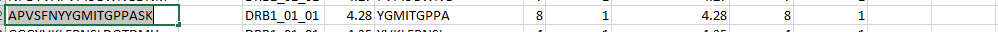

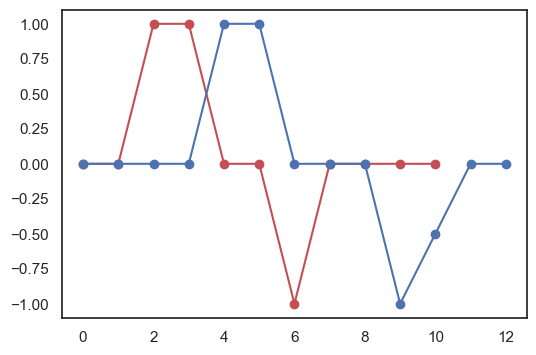

In [28]:
x = np.array([0, 0, 1, 1, 0, 0, -1, 0, 0, 0, 0])
y = np.array([0, 0, 0, 0, 1, 1, 0, 0, 0, -1, -0.5, 0, 0])

plt.figure(figsize=(6, 4))
plt.plot(np.arange(x.shape[0]), x, "-o", c="C3")
plt.plot(np.arange(y.shape[0]), y, "-o", c="C0")

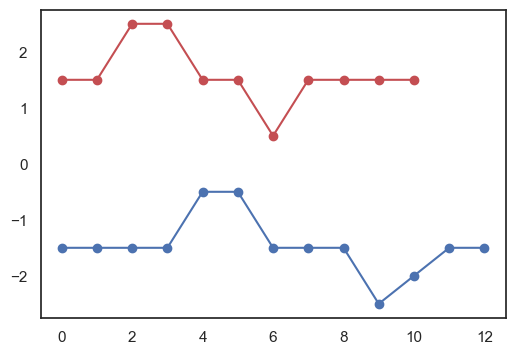

In [29]:
x = np.array([0, 0, 1, 1, 0, 0, -1, 0, 0, 0, 0])
y = np.array([0, 0, 0, 0, 1, 1, 0, 0, 0, -1, -0.5, 0, 0])

plt.figure(figsize=(6, 4))
plt.plot(np.arange(x.shape[0]), x + 1.5, "-o", c="C3")
plt.plot(np.arange(y.shape[0]), y - 1.5, "-o", c="C0")
#plt.axis("off")


In [30]:


# Distance matrix
N = x.shape[0]
M = y.shape[0]
dist_mat = np.zeros((N, M))
for i in range(N):
    for j in range(M):
        dist_mat[i, j] = abs(x[i] - y[j])



In [31]:
import seaborn as sns

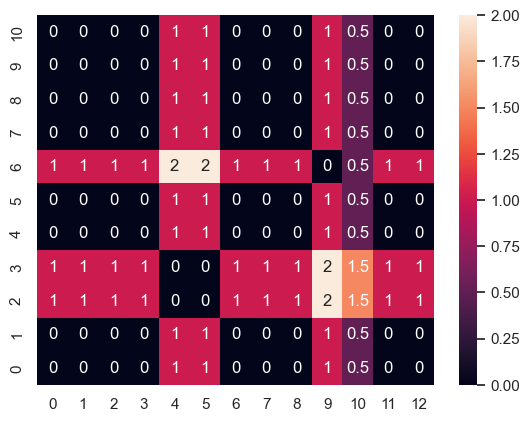

In [32]:
ax = sns.heatmap(dist_mat, annot=True)
ax.invert_yaxis()

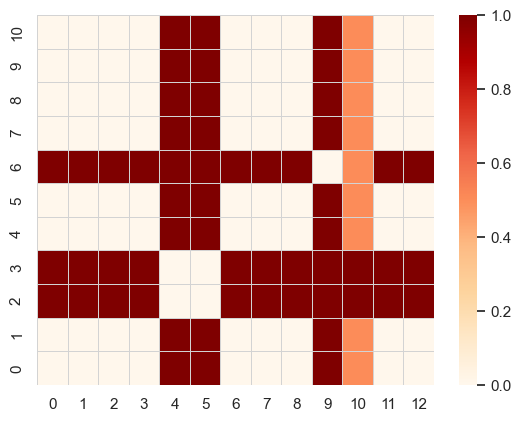

In [33]:
# dist_mat = np.zeros((N, M))
ax = sns.heatmap(dist_mat,  linewidth=.5, cmap="OrRd",linecolor='lightgray', vmin=0, vmax=1)
ax.invert_yaxis()

In [34]:
path, cost_mat = dp(dist_mat)

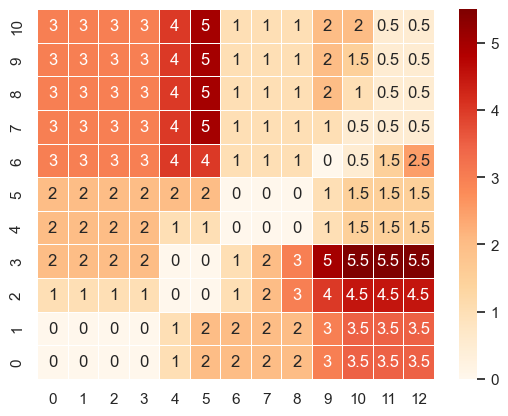

In [35]:
ax = sns.heatmap(cost_mat,  linewidth=.5, cmap="OrRd", annot=True)
ax.invert_yaxis()

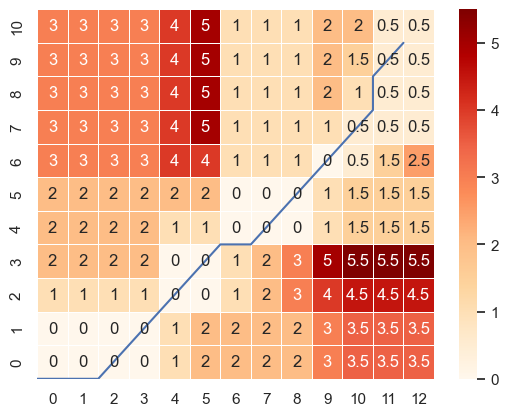

In [36]:
x_path, y_path = zip(*path)
ax = sns.heatmap(cost_mat,  linewidth=.5, cmap="OrRd", annot=True)
ax.invert_yaxis()
plt.plot(y_path, x_path)

In [37]:
def plot_matrices(x, y, mat, annot=True, marker="o"):
    sz_x = x.shape[0]
    sz_y = y.shape[0]
    plt.figure(1, figsize=(8, 8))
    # definitions for the axes
    left, bottom = 0.01, 0.1
    w_ts = h_ts = 0.2
    left_h = left + w_ts + 0.02
    width = height = 0.65
    bottom_h = bottom + height + 0.02

    rect_s_y = [left, bottom, w_ts, height]
    rect_gram = [left_h, bottom, width, height]
    rect_s_x = [left_h, bottom_h, width, h_ts]

    ax_gram = plt.axes(rect_gram)

    x_path, y_path = zip(*path)
    ax = sns.heatmap(mat,  linewidth=.5, cmap="OrRd", annot=annot, ax=ax_gram, cbar=False, annot_kws={"fontsize":8})
    ax.invert_yaxis()
    #Set all sides
    ax.tick_params(left=False, labelleft=False, right=True, labelright=True,rotation=0)



    plt.plot(y_path, x_path)

    ax_s_x = plt.axes(rect_s_x)
    ax_s_y = plt.axes(rect_s_y)

    ax_s_x.plot(np.arange(sz_y), y, "b-",marker=marker, linewidth=1.)
    ax_s_x.axis("off")

    ax_s_x.set_xlim((0, sz_y - 1))
    ticks_location_x = [np.min(y), np.mean(y), np.max(y)]
    ticks_labels_x = [str(round(loc, 2)) for loc in ticks_location_x]
    # ticks_labels = [r"$\bf -v $", r"$\bf0$", r"$\bf v$"]
    ax_s_x.plot([0, sz_y - 1], [ticks_location_x]*2, "k--", alpha=.2)

    indexes_location_x = np.arange(sz_y)



    ax_s_y.plot(-x, np.arange(sz_x), "g-", marker=marker,linewidth=1.)
    ax_s_y.axis("off")
    ax_s_y.set_ylim((0, sz_x - 1))
    ticks_location_y = [np.min(x), np.mean(x), np.max(x)]
    ticks_labels_y = [str(round(loc, 2)) for loc in ticks_location_y]
    ax_s_y.plot([ticks_location_y]*2, [0, sz_x - 1], "k--", alpha=.2)


    for loc, s in zip(ticks_location_x, ticks_labels_x):
        ax_s_x.text(0, loc, s, fontsize="large", color="grey",
                    horizontalalignment="right", verticalalignment="center")




    for loc, s in zip(ticks_location_y, ticks_labels_y):
        ax_s_y.text(-loc, 0, s, fontsize="large", color="grey",
                    horizontalalignment="center", verticalalignment="top")






    plt.tight_layout()
    plt.show()

C:\Users\denkl\AppData\Local\Temp\ipykernel_25100\72974500.py:68: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


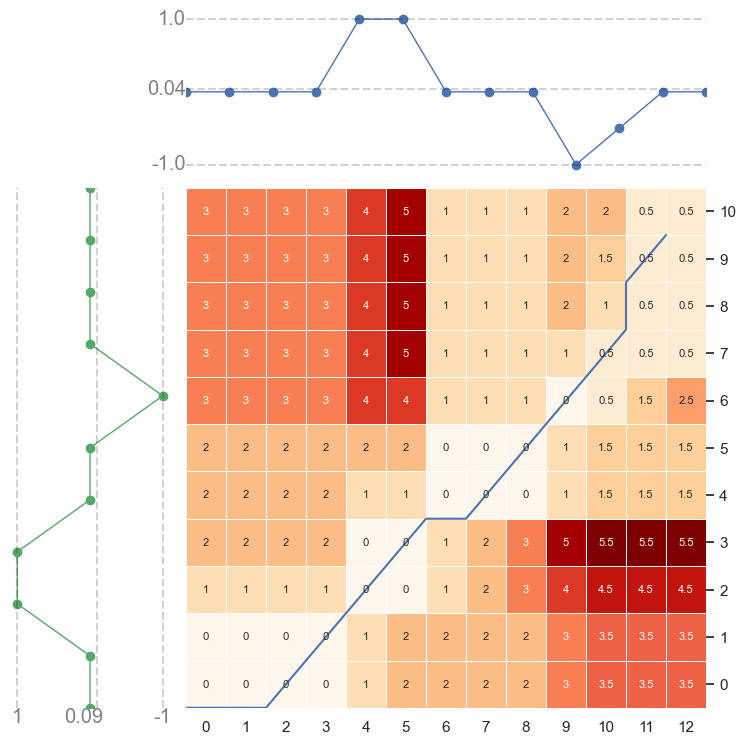

In [38]:
plot_matrices(x, y, cost_mat)

(-0.6000000000000001, 12.6, -2.75, 2.75)

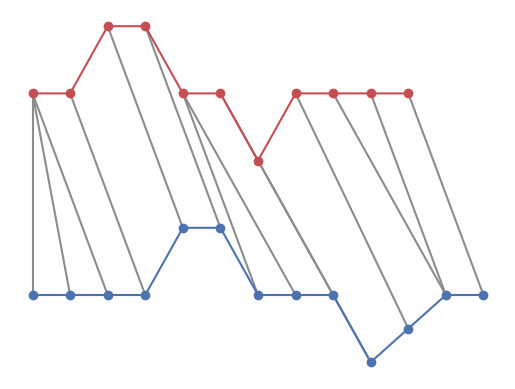

In [39]:
plt.figure()
for x_i, y_j in path:
    plt.plot([x_i, y_j], [x[x_i] + 1.5, y[y_j] - 1.5], c="C7")
plt.plot(np.arange(x.shape[0]), x + 1.5, "-o", c="C3")
plt.plot(np.arange(y.shape[0]), y - 1.5, "-o", c="C0")
plt.axis("off")

# Peptides

In [40]:
peptide_df = pd.concat(dfs)

peptide_df = peptide_df[peptide_df['length'].isin(TARGET_LENGTHS)]
peptide_df = peptide_df[peptide_df['split'].isin([0])]
peptide_df = peptide_df.reset_index(drop=True)

pep1_index = peptide_df[peptide_df.peptide =='KDSYVELASAKVRPQ'].index[0] # core start from 4 or 5
pep2_index = peptide_df[peptide_df.peptide =='APVSFNYYGMITGPPASK'].index[0] # core start from  8?

list_peptides = [list(peptide) for peptide in peptide_df.peptide.values]
converted_peptides = [np.array([[transform_dict[aa] for transform_dict in transform_dicts] for aa in  peptide]) for peptide in list_peptides]



sel_property = 4
peptide1 = converted_peptides[pep1_index]
peptide2 = converted_peptides[pep2_index]
print(peptide1.shape)
x = peptide1[:, sel_property]
y = peptide2[:, sel_property]

(15, 73)


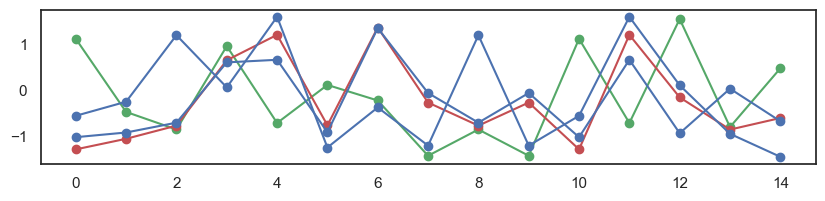

In [61]:
plt.figure(figsize=(10, 2))
plt.plot(converted_peptides[pep1_index][:, 0], c='g', marker="o")
plt.plot(converted_peptides[pep1_index][:, 1], c='r', marker="o")
plt.plot(converted_peptides[pep1_index][:, -1], c='b', marker="o")
plt.plot(converted_peptides[pep1_index][:, 4], c='b', marker="o")

In [41]:
 peptide_df[peptide_df.peptide =='APVSFNYYGMITGPPASK']

,peptide,length,allele,split
5603,APVSFNYYGMITGPPASK,18,HLA-DRB1*01:01,0


In [42]:
pep2_index

5603

In [43]:
x.shape, y.shape

((15,), (18,))

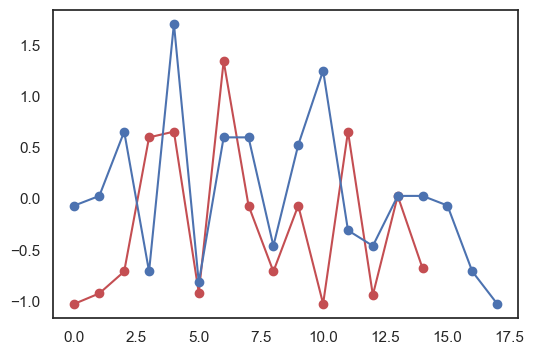

In [44]:
plt.figure(figsize=(6, 4))
plt.plot(np.arange(x.shape[0]), x, "-o", c="C3")
plt.plot(np.arange(y.shape[0]), y, "-o", c="C0")

In [45]:
pep1 = x
pep2 = y

In [46]:
x.shape

(15,)

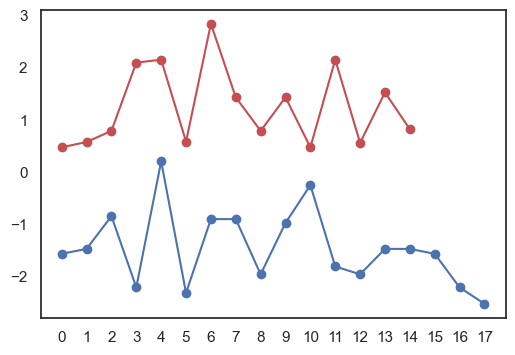

In [47]:
plt.figure(figsize=(6, 4))
plt.plot(np.arange(x.shape[0]), x + 1.5, "-o", c="C3")
plt.plot(np.arange(y.shape[0]), y - 1.5, "-o", c="C0")
ax =plt.gca()
ax.set_xticks(np.arange(0, y.shape[0]))
#plt.axis("off")

In [48]:
# Distance matrix
N = x.shape[0]
M = y.shape[0]
dist_mat = np.zeros((N, M))
for i in range(N):
    for j in range(M):
            # s_x = np.zeros(5)
            # s_x[2] = x[i]
            # s_x[1] = x[i - 1] if i >= 1 else 1
            # s_x[0] = x[i - 2] if i >= 2 else 1
            # s_x[3] = x[i + 1] if i <= N-2 else 1
            # s_x[4] = x[i + 2] if i <= N-3 else 1
            # s_y = np.zeros(5)
            # s_y[2] = y[j]
            # s_y[1] = y[j - 1] if i >= 1 else 1
            # s_y[0] = y[j - 2] if j >= 2 else 1
            # s_y[3] = y[j + 1] if j <= M-2 else 1
            # s_y[4] = y[j  +2] if j <= M-3 else 1
            # dist_mat[i, j] = distance.correlation(s_x,  s_y)
            dist_mat[i,j] = abs(x[i] - y[j])
            #dist_mat[i,j] = abs(x[i] - y[j])



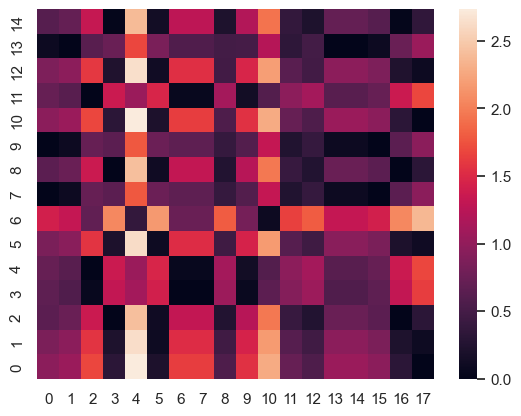

In [135]:
ax = sns.heatmap(dist_mat)
ax.invert_yaxis()

In [136]:
# DTW
path, cost_mat = dp(dist_mat)
print("Alignment cost: {:.4f}".format(cost_mat[N - 1, M - 1]))
print("Normalized alignment cost: {:.4f}".format(cost_mat[N - 1, M - 1]/(N + M)))

Alignment cost: 8.2399
Normalized alignment cost: 0.2497


C:\Users\denkl\AppData\Local\Temp\ipykernel_23852\2990878372.py:68: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


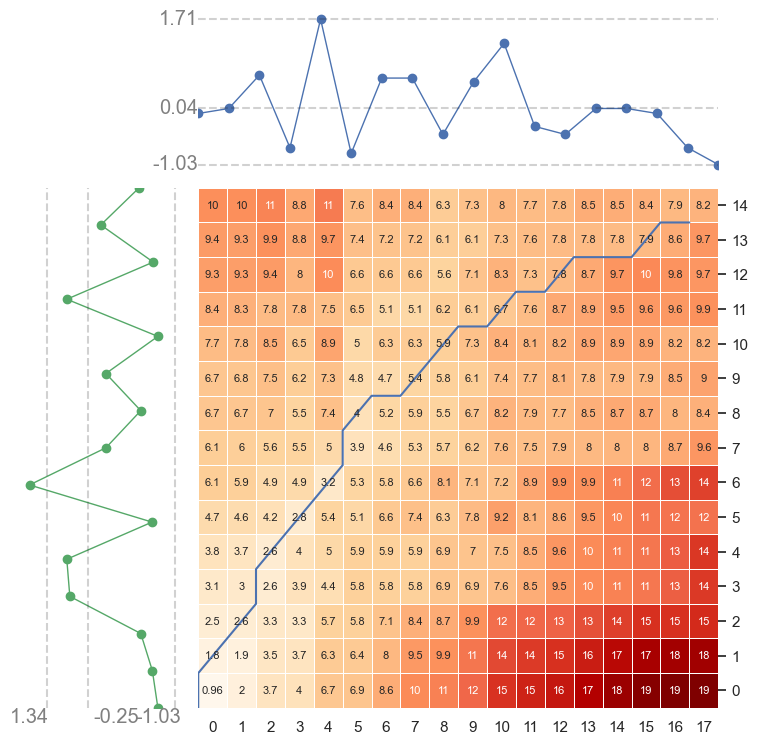

In [137]:
plot_matrices(x,y,cost_mat)

C:\Users\denkl\AppData\Local\Temp\ipykernel_23852\2990878372.py:68: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


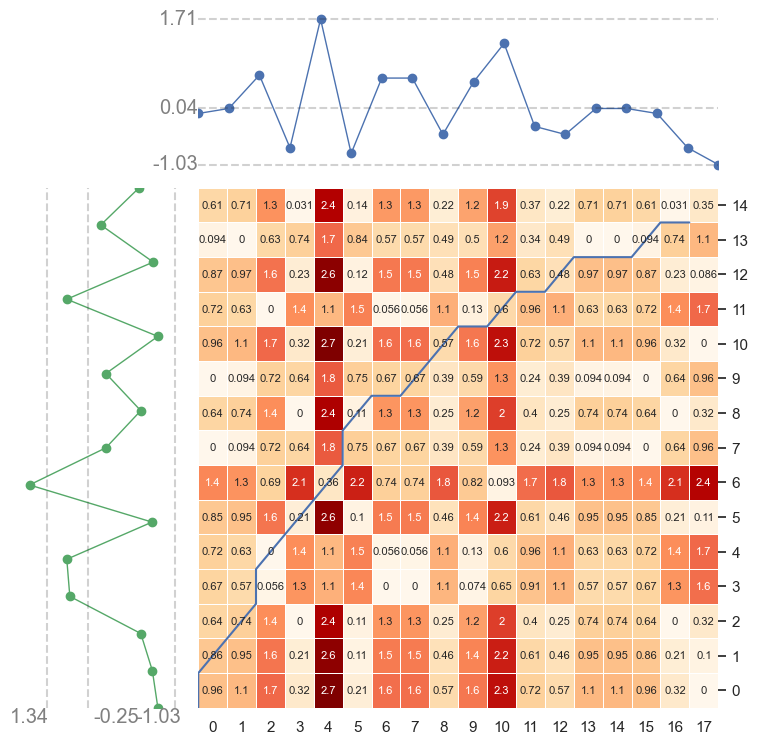

In [138]:
plot_matrices(x,y,dist_mat)

(-0.8500000000000001, 17.85, -2.794713395663568, 3.109758990266844)

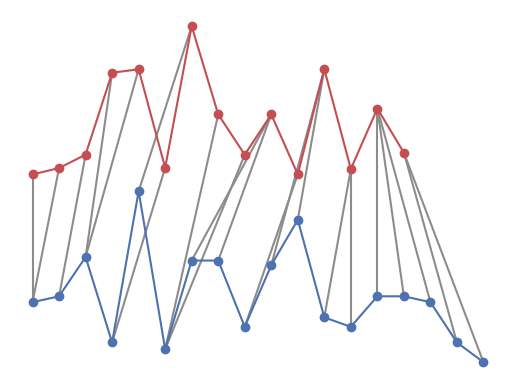

In [140]:
plt.figure()
for x_i, y_j in path:
    plt.plot([x_i, y_j], [x[x_i] + 1.5, y[y_j] - 1.5], c="C7")
plt.plot(np.arange(x.shape[0]), x + 1.5, "-o", c="C3")
plt.plot(np.arange(y.shape[0]), y - 1.5, "-o", c="C0")
plt.axis("off")

## get best property

In [143]:

from scipy.spatial import distance


In [144]:
result_paths = list()
result_cost_mats = list()
for sel_property in range(len(transform_dicts)):
    x = peptide1[:, sel_property]
    y = peptide2[:, sel_property]
    N = x.shape[0]
    M = y.shape[0]
    dist_mat = np.zeros((N, M))
    for i in range(N):
        for j in range(M):
            dist_mat[i, j] = abs(x[i] - y[j])
    for i in range(N):
        for j in range(M):
#             s_x = np.zeros(3)
            
#             s_x[0] = x[i]
#             s_x[1] = x[i - 1] if i >= 1 else 0.1
#             s_x[2] = x[i + 1] if i <= N-2 else 0.1
#             s_y = np.zeros(3)
#             s_y[0] = y[j]
#             s_y[1] = y[j - 1] if i >= 1 else 0.1
#             s_y[2] = y[j + 1] if j <= M-2 else 0.1

#             dist_mat[i, j] = distance.cosine(s_x,  s_y)
              dist_mat[i, j] = abs(x[i] - y[j])
            
            
           # abs(x[i] - y[j])
   # dist_mat = dist.cdist(x, y, "cosine")
            
            
    path, cost_mat = dp(dist_mat)
    result_paths.append(path)
    result_cost_mats.append(cost_mat)

    

In [145]:
costs = [cost_mat[N - 1, M - 1]/(N + M) for cost_mat in result_cost_mats]
pd.DataFrame(costs)

,0
0,0.368366
1,0.253380
2,0.268855
3,0.227866
4,0.249694
...,...
68,0.223611
69,0.289956
70,0.248265
71,0.317947


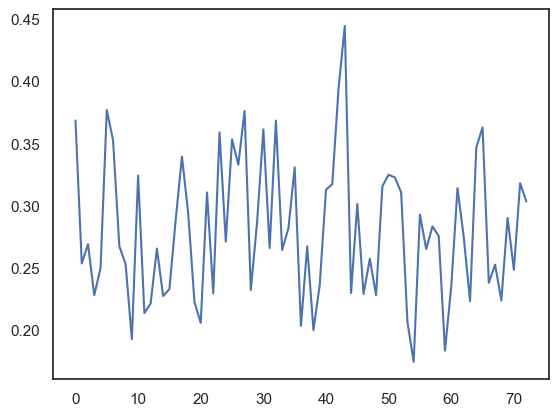

In [146]:
plt.plot(costs)

In [150]:
best_property = np.argmin(costs)

In [151]:
path = result_paths[best_property]
cost_mat = result_cost_mats[best_property]

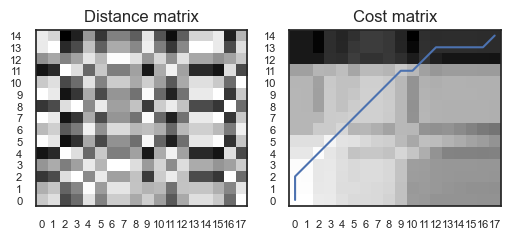

In [152]:
plt.figure(figsize=(6, 4))
plt.subplot(121)
plt.title("Distance matrix")
plt.imshow(dist_mat, cmap=plt.cm.binary, interpolation="nearest", origin="lower")
ax = plt.gca()
ax.set_xticks(np.arange(0, dist_mat.shape[1]))
ax.set_yticks(np.arange(0, dist_mat.shape[0]))
ax.tick_params(axis='both', labelsize=8)
ax.tick_params(axis='both', labelsize=8)
plt.subplot(122)
plt.title("Cost matrix")
plt.imshow(cost_mat, cmap=plt.cm.binary, interpolation="nearest", origin="lower")
ax = plt.gca()
ax.set_xticks(np.arange(0, cost_mat.shape[1]))
ax.set_yticks(np.arange(0, cost_mat.shape[0]))
ax.tick_params(axis='both', labelsize=8)
ax.tick_params(axis='both', labelsize=8)
x_path, y_path = zip(*path)
plt.plot(y_path, x_path);

(-0.8500000000000001, 17.85, -4.64886849507396, 5.026543441123952)

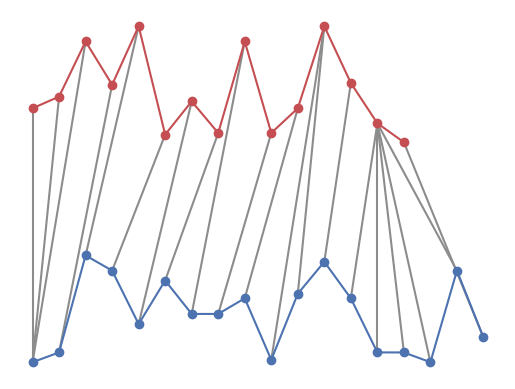

In [153]:
plt.figure()
for x_i, y_j in path:
    plt.plot([x_i, y_j], [x[x_i] + 3, y[y_j] - 3], c="C7")
plt.plot(np.arange(x.shape[0]), x + 3, "-o", c="C3")
plt.plot(np.arange(y.shape[0]), y - 3, "-o", c="C0")
plt.axis("off")

C:\Users\denkl\AppData\Local\Temp\ipykernel_23852\2990878372.py:68: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


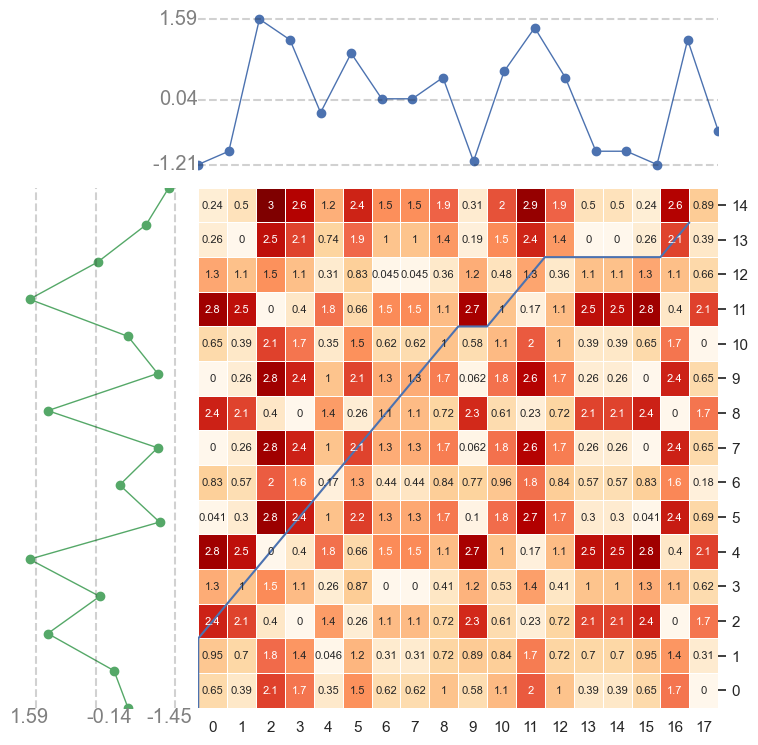

In [154]:
plot_matrices(x,y,dist_mat)

C:\Users\denkl\AppData\Local\Temp\ipykernel_23852\2990878372.py:68: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


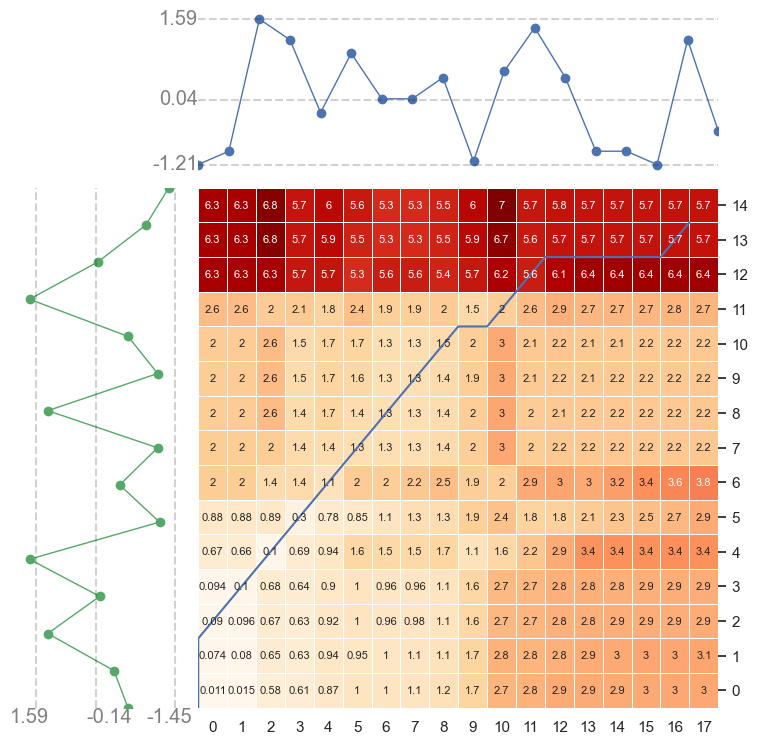

In [155]:
plot_matrices(x,y,cost_mat)

## Interpolate

(15, 73)


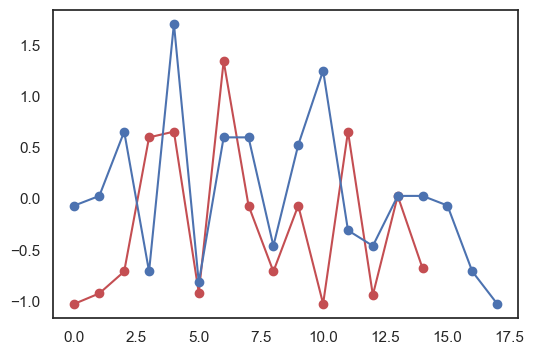

In [166]:
peptide_df = pd.concat(dfs)

peptide_df = peptide_df[peptide_df['length'].isin(TARGET_LENGTHS)]
peptide_df = peptide_df[peptide_df['split'].isin([0])]
peptide_df = peptide_df.reset_index(drop=True)

pep1_index = peptide_df[peptide_df.peptide =='KDSYVELASAKVRPQ'].index[0] # core start from 4 or 5
pep2_index = peptide_df[peptide_df.peptide =='APVSFNYYGMITGPPASK'].index[0] # core start from  8?

list_peptides = [list(peptide) for peptide in peptide_df.peptide.values]
converted_peptides = [np.array([[transform_dict[aa] for transform_dict in transform_dicts] for aa in  peptide]) for peptide in list_peptides]



sel_property = 4
peptide1 = converted_peptides[pep1_index]
peptide2 = converted_peptides[pep2_index]
print(peptide1.shape)
x = peptide1[:, sel_property]
y = peptide2[:, sel_property]

plt.figure(figsize=(6, 4))
plt.plot(np.arange(x.shape[0]), x, "-o", c="C3")
plt.plot(np.arange(y.shape[0]), y, "-o", c="C0")

In [167]:
def interpolate_peptide(old_y_vals):
    old_x_vals = np.arange(old_y_vals.shape[0])
    x_vals =  np.linspace(0, old_y_vals.shape[0], 100)
    y_vals = np.interp(x_vals, old_x_vals, old_y_vals)
    return y_vals
    
    

In [168]:
x = interpolate_peptide(x)
y = interpolate_peptide(y)

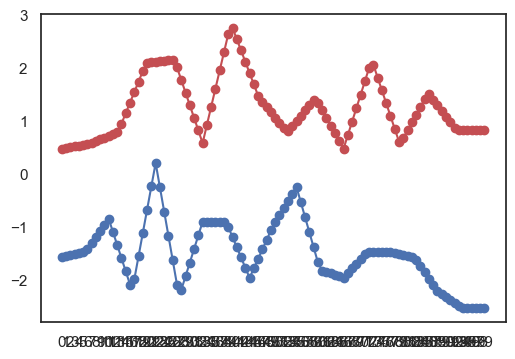

In [169]:
plt.figure(figsize=(6, 4))
plt.plot(np.arange(x.shape[0]), x + 1.5, "-o", c="C3")
plt.plot(np.arange(y.shape[0]), y - 1.5, "-o", c="C0")
ax =plt.gca()
ax.set_xticks(np.arange(0, y.shape[0]))

print()

In [170]:
# Distance matrix
N = x.shape[0]
M = y.shape[0]
dist_mat = np.zeros((N, M))
for i in range(N):
    for j in range(M):
            # s_x = np.zeros(5)
            # s_x[2] = x[i]
            # s_x[1] = x[i - 1] if i >= 1 else 1
            # s_x[0] = x[i - 2] if i >= 2 else 1
            # s_x[3] = x[i + 1] if i <= N-2 else 1
            # s_x[4] = x[i + 2] if i <= N-3 else 1
            # s_y = np.zeros(5)
            # s_y[2] = y[j]
            # s_y[1] = y[j - 1] if i >= 1 else 1
            # s_y[0] = y[j - 2] if j >= 2 else 1
            # s_y[3] = y[j + 1] if j <= M-2 else 1
            # s_y[4] = y[j  +2] if j <= M-3 else 1
            # dist_mat[i, j] = distance.correlation(s_x,  s_y)
            dist_mat[i,j] = abs(x[i] - y[j])
            #dist_mat[i,j] = abs(x[i] - y[j])

In [172]:
# DTW
path, cost_mat = dp(dist_mat)
print("Alignment cost: {:.4f}".format(cost_mat[N - 1, M - 1]))
print("Normalized alignment cost: {:.4f}".format(cost_mat[N - 1, M - 1]/(N + M)))

Alignment cost: 33.1277
Normalized alignment cost: 0.1656


C:\Users\denkl\AppData\Local\Temp\ipykernel_23852\600268605.py:68: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


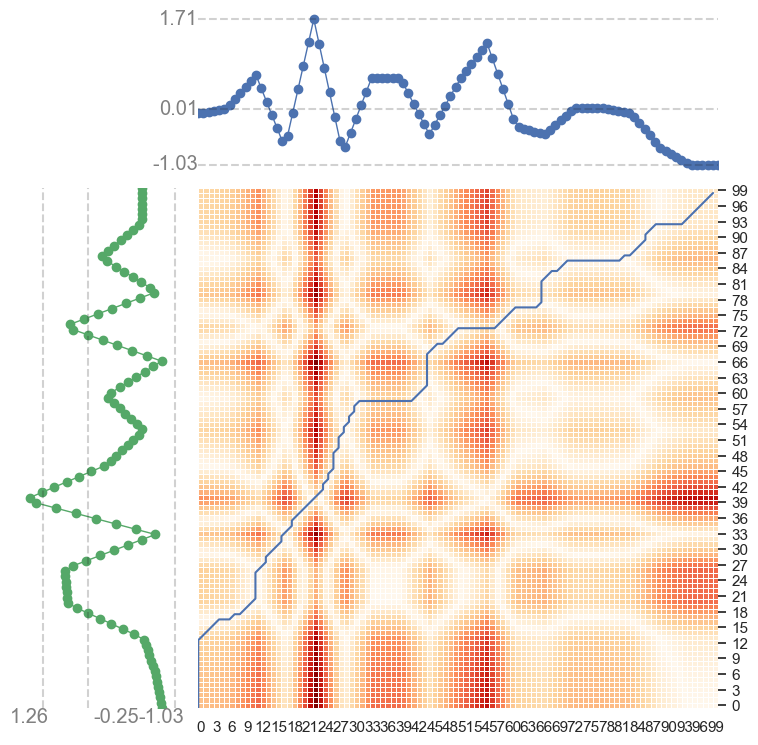

In [173]:
plot_matrices(x,y,dist_mat, annot=False)

C:\Users\denkl\AppData\Local\Temp\ipykernel_23852\600268605.py:68: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


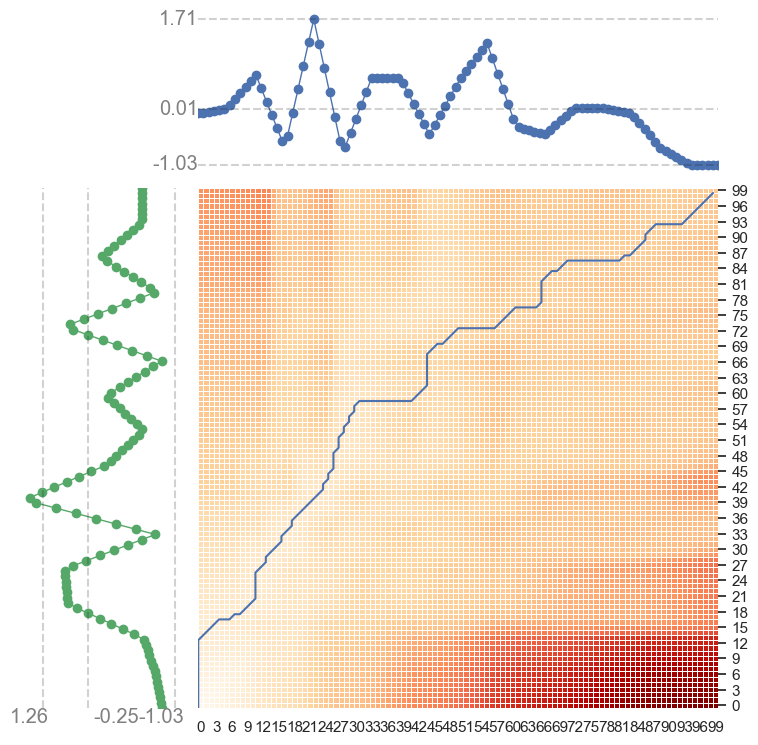

In [174]:
plot_matrices(x,y,cost_mat, annot=False)

(-4.95, 103.95, -4.440443996913889, 4.670101616523585)

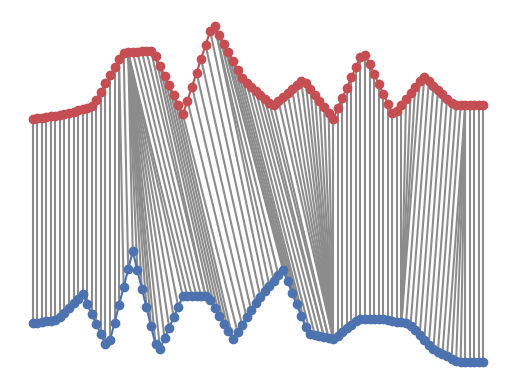

In [195]:
plt.figure()
for x_i, y_j in path:
    plt.plot([x_i, y_j], [x[x_i] + 3, y[y_j] - 3], c="C7")
plt.plot(np.arange(x.shape[0]), x + 3, "-o", c="C3")
plt.plot(np.arange(y.shape[0]), y - 3, "-o", c="C0")
plt.axis("off")

## Simple sliding window

In [191]:
# Distance matrix
N = x.shape[0]
M = y.shape[0]
window_size = 11
dist_mat = np.zeros((N, M))
for i in range(N):
    for j in range(M):
            s_x = np.zeros(window_size)
            s_y = np.zeros(window_size)
            half_size = int(window_size/2)
            s_x[half_size + 1] = x[i]
            s_y[half_size + 1] = y[j]
            for k in range(half_size):
                s_x[k] = x[i - half_size + k -1] if i >=  k+1 else 0
                s_x[half_size + k] = x[i + k] if i <=   N-(k+1) else 0
                
                s_y[k] = y[j - half_size + k -1] if j >=  k+1 else 0
                s_y[half_size + k] = y[j + k] if j <=   M-(k+1) else 0
  
            
            dist_mat[i, j] = distance.euclidean(s_x,  s_y)
            # dist_mat[i,j] = abs(x[i] - y[j])
            #dist_mat[i,j] = abs(x[i] - y[j])

In [192]:
# DTW
path, cost_mat = dp(dist_mat)
print("Alignment cost: {:.4f}".format(cost_mat[N - 1, M - 1]))
print("Normalized alignment cost: {:.4f}".format(cost_mat[N - 1, M - 1]/(N + M)))

Alignment cost: 163.5757
Normalized alignment cost: 0.8179


C:\Users\denkl\AppData\Local\Temp\ipykernel_23852\600268605.py:68: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


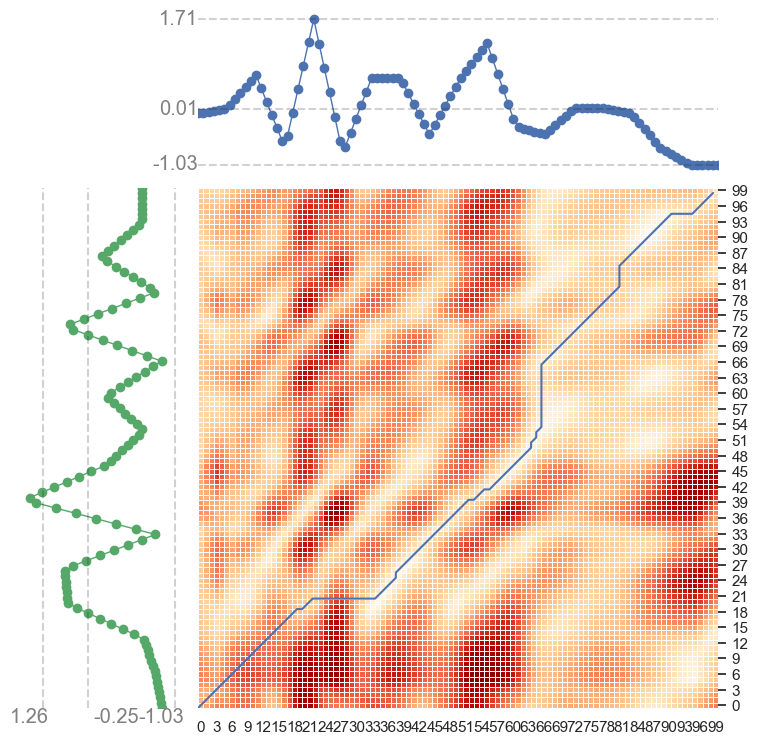

In [193]:
plot_matrices(x,y,dist_mat, annot=False)

C:\Users\denkl\AppData\Local\Temp\ipykernel_23852\600268605.py:68: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


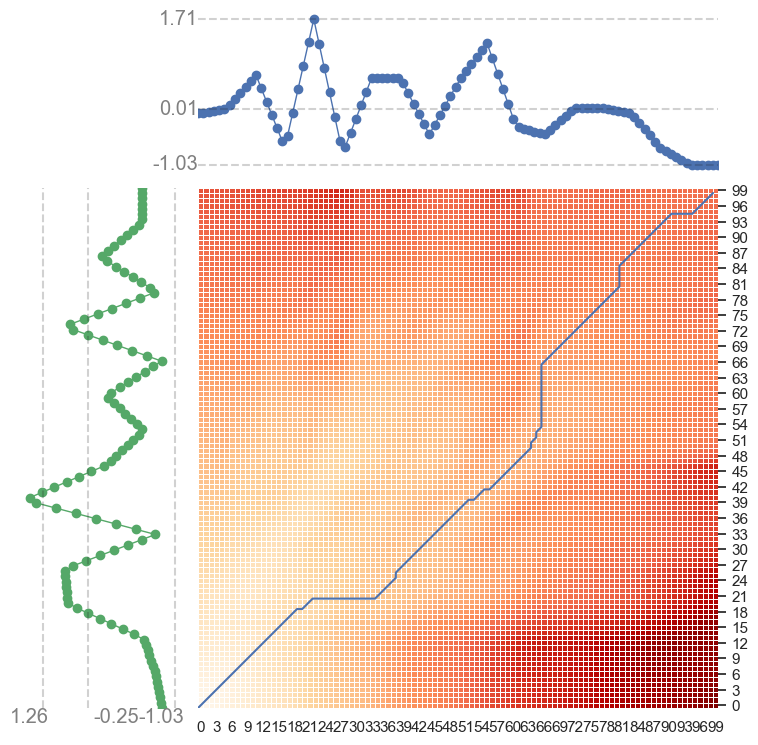

In [194]:
plot_matrices(x,y,cost_mat, annot=False)

## Multivariate examples

In [206]:
converted_peptides[pep1_index].T.shape

(73, 15)

In [207]:
pep1_index = peptide_df[peptide_df.peptide =='KDSYVELASAKVRPQ'].index[0] # core start from 4 or 5
pep2_index = peptide_df[peptide_df.peptide =='APVSFNYYGMITGPPASK'].index[0] # core start from  8


peptide1 = converted_peptides[pep1_index].T[:20,:]
peptide2 = converted_peptides[pep2_index].T[:20,:]

In [208]:
peptide1.shape

(20, 15)

In [209]:
peptide2.shape

(20, 18)

In [210]:
import IPython.display as ipyd

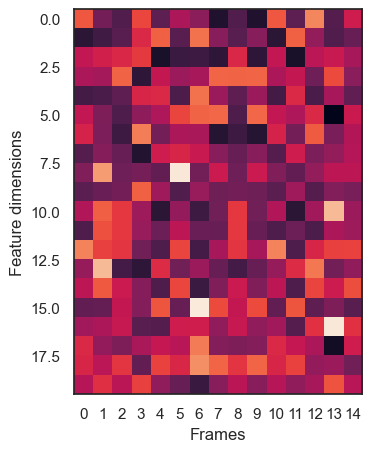

In [211]:


# Spectrogran
# n_fft = int(0.025*f_s)      # 25 ms
# hop_length = int(0.01*f_s)  # 10 ms
# mel_spec_x = librosa.feature.melspectrogram(
#     x/1.0, sr=f_s, n_mels=40,
#     n_fft=n_fft, hop_length=hop_length
#     )
# log_mel_spec_x = np.log(mel_spec_x)

# Plot log-Mel spectrogram
fig, ax = plt.subplots(figsize=(9, 5))
ax.imshow(peptide1);
ax.set_xticks(np.arange(0, peptide1.shape[1]))

plt.ylabel("Feature dimensions")
plt.xlabel("Frames");



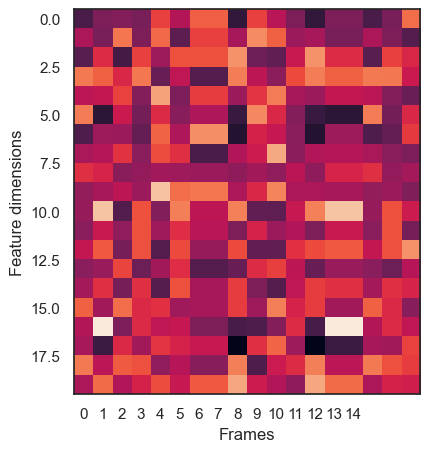

In [212]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.imshow(peptide2);
plt.ylabel("Feature dimensions")
ax.set_xticks(np.arange(0, peptide1.shape[1]))
plt.xlabel("Frames");


In [213]:


x_seq = peptide1.T
y_seq = peptide2.T

dist_mat = dist.cdist(x_seq, y_seq, "cosine")
path, cost_mat = dp(dist_mat)
print("Alignment cost: {:.4f}".format(cost_mat[-1, -1]))



Alignment cost: 12.3493


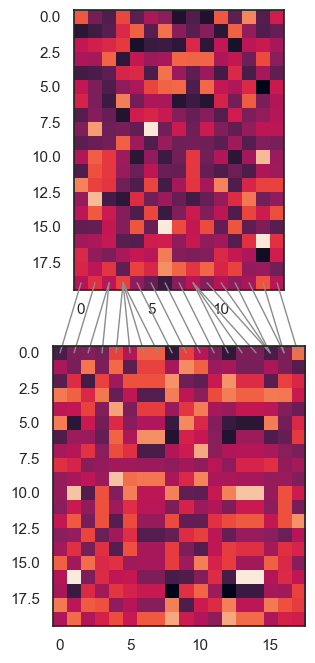

In [214]:
fig = plt.figure(figsize=(16,8))
ax1 = fig.add_subplot(211)
ax2 = fig.add_subplot(212)

ax1.imshow(peptide1 )
ax2.imshow(peptide2)


for x_i, y_j in path:
    con = ConnectionPatch(
        xyA=(x_i, peptide2.shape[0]-1), xyB=(y_j, 0), coordsA="data", coordsB="data",
        axesA=ax1, axesB=ax2, color="C7"
        )
    ax2.add_artist(con)

C:\Users\denkl\AppData\Local\Temp\ipykernel_23852\600268605.py:68: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


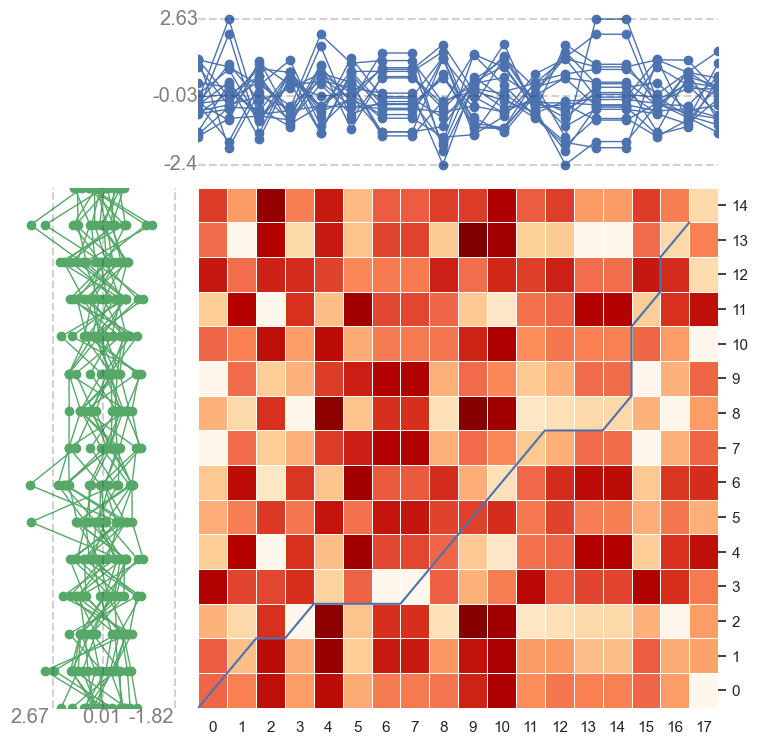

In [215]:
plot_matrices(x_seq,y_seq,dist_mat, annot=False)

C:\Users\denkl\AppData\Local\Temp\ipykernel_23852\600268605.py:68: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


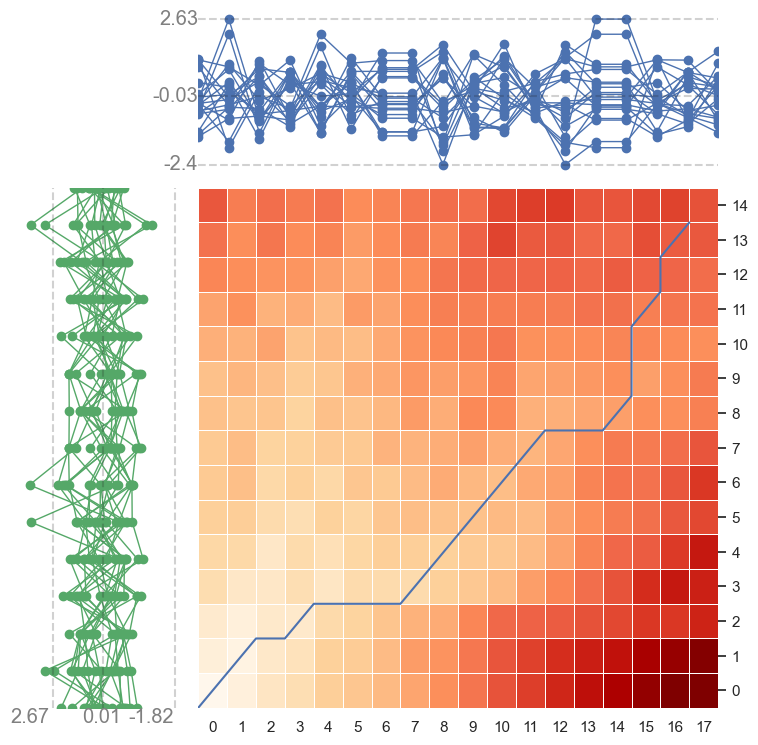

In [216]:
plot_matrices(x_seq,y_seq,cost_mat, annot=False)

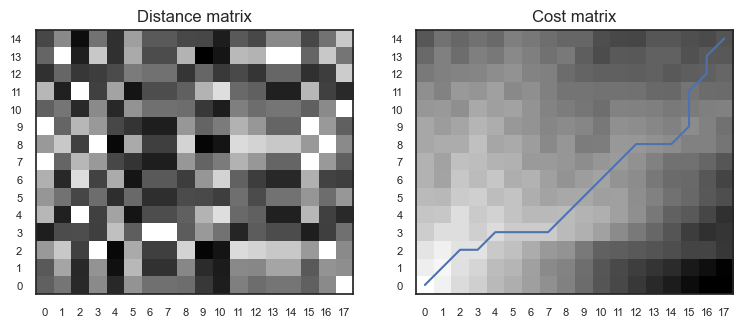

In [679]:


plt.figure(figsize=(9, 5))
plt.subplot(121)
plt.title("Distance matrix")
plt.imshow(dist_mat, cmap=plt.cm.binary, interpolation="nearest", origin="lower")
ax = plt.gca()
ax = plt.gca()
ax.set_xticks(np.arange(0, dist_mat.shape[1]))
ax.set_yticks(np.arange(0, dist_mat.shape[0]))
ax.tick_params(axis='both', labelsize=8)
ax.tick_params(axis='both', labelsize=8)
plt.subplot(122)
plt.title("Cost matrix")
plt.imshow(cost_mat, cmap=plt.cm.binary, interpolation="nearest", origin="lower")
ax = plt.gca()
ax.set_xticks(np.arange(0, cost_mat.shape[1]))
ax.set_yticks(np.arange(0, cost_mat.shape[0]))
ax.tick_params(axis='both', labelsize=8)
ax.tick_params(axis='both', labelsize=8)
x_path, y_path = zip(*path)
plt.plot(y_path, x_path);
# Set xticks and yticks

#

## Interpolate again

In [219]:
def interpolate_peptide(old_y_vals):
    old_x_vals = np.arange(old_y_vals.shape[0])
    x_vals =  np.linspace(0, old_y_vals.shape[0], 100)
    y_vals = np.zeros((100, old_y_vals.shape[1]))
    for i in range(old_y_vals.shape[1]):
        y_vals[:, i] = np.interp(x_vals, old_x_vals, old_y_vals[:, i])
        
   # y_vals = np.interp(x_vals, old_x_vals, old_y_vals)
    return y_vals

In [220]:
x.shape

(15, 20)

In [221]:




pep1_index = peptide_df[peptide_df.peptide =='KDSYVELASAKVRPQ'].index[0] # core start from 4 or 5
pep2_index = peptide_df[peptide_df.peptide =='APVSFNYYGMITGPPASK'].index[0] # core start from  8


peptide1 = converted_peptides[pep1_index].T[:20,:]
peptide2 = converted_peptides[pep2_index].T[:20,:]

x = peptide1.T
y = peptide2.T
x = interpolate_peptide(x)
y = interpolate_peptide(y)

In [224]:
x.shape

(100, 20)

In [222]:
dist_mat = dist.cdist(x, y, "cosine")
path, cost_mat = dp(dist_mat)
print("Alignment cost: {:.4f}".format(cost_mat[-1, -1]))


Alignment cost: 69.1532


In [226]:
len(path)

133

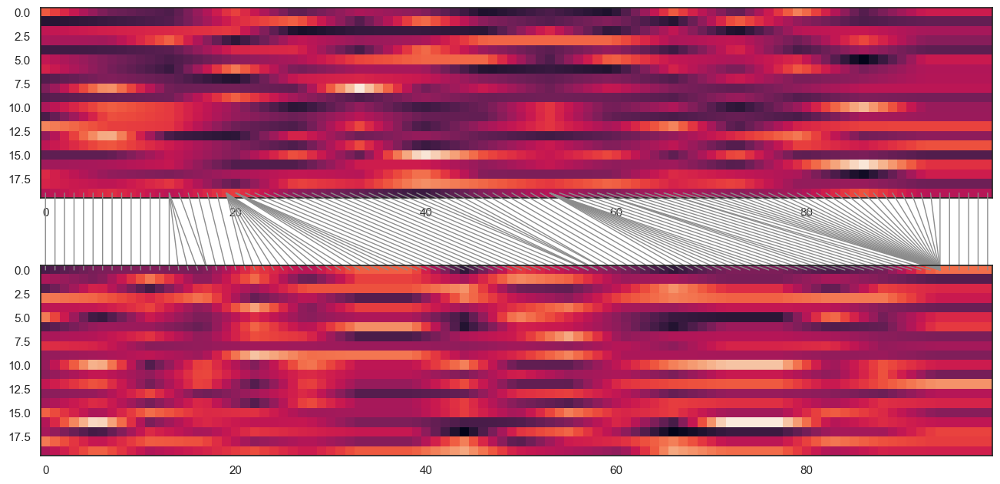

In [228]:
fig = plt.figure(figsize=(16,8))
ax1 = fig.add_subplot(211)
ax2 = fig.add_subplot(212)

ax1.imshow(x.T )
ax2.imshow(y.T)


for x_i, y_j in path:
    con = ConnectionPatch(
        xyA=(x_i, y.T.shape[0]-1), xyB=(y_j, 0), coordsA="data", coordsB="data",
        axesA=ax1, axesB=ax2, color="C7"
        )
    ax2.add_artist(con)

C:\Users\denkl\AppData\Local\Temp\ipykernel_23852\72974500.py:68: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


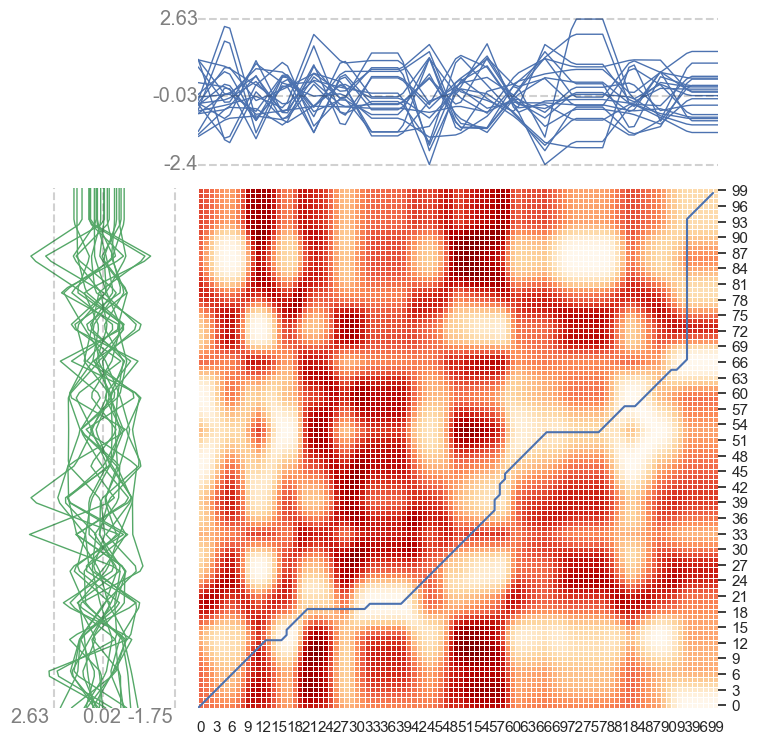

In [233]:
plot_matrices(x,y,dist_mat, annot=False, marker=None)

C:\Users\denkl\AppData\Local\Temp\ipykernel_23852\72974500.py:68: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


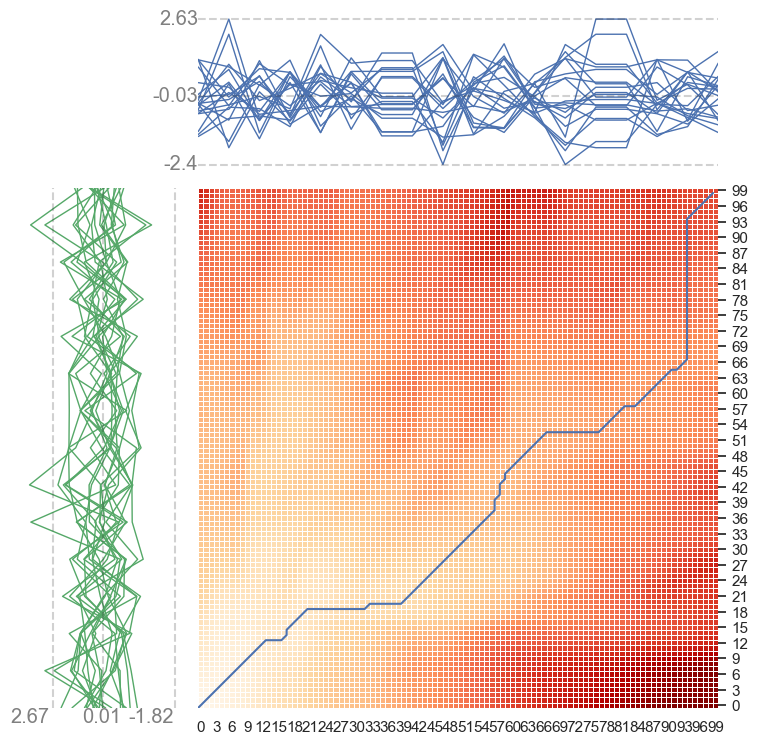

In [234]:
plot_matrices(x_seq,y_seq,cost_mat, annot=False, marker=None)

## More properties

In [237]:



pep1_index = peptide_df[peptide_df.peptide =='KDSYVELASAKVRPQ'].index[0] # core start from 4 or 5
pep2_index = peptide_df[peptide_df.peptide =='APVSFNYYGMITGPPASK'].index[0] # core start from  8


peptide1 = converted_peptides[pep1_index].T
peptide2 = converted_peptides[pep2_index].T

x = peptide1.T
y = peptide2.T
x = interpolate_peptide(x)
y = interpolate_peptide(y)

In [238]:
dist_mat = dist.cdist(x, y, "cosine")
path, cost_mat = dp(dist_mat)
print("Alignment cost: {:.4f}".format(cost_mat[-1, -1]))


Alignment cost: 84.0447


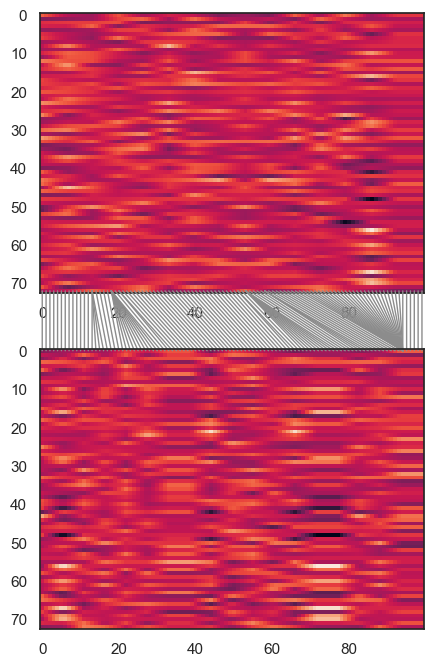

In [239]:
fig = plt.figure(figsize=(16,8))
ax1 = fig.add_subplot(211)
ax2 = fig.add_subplot(212)

ax1.imshow(x.T )
ax2.imshow(y.T)


for x_i, y_j in path:
    con = ConnectionPatch(
        xyA=(x_i, y.T.shape[0]-1), xyB=(y_j, 0), coordsA="data", coordsB="data",
        axesA=ax1, axesB=ax2, color="C7"
        )
    ax2.add_artist(con)

C:\Users\denkl\AppData\Local\Temp\ipykernel_23852\72974500.py:68: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


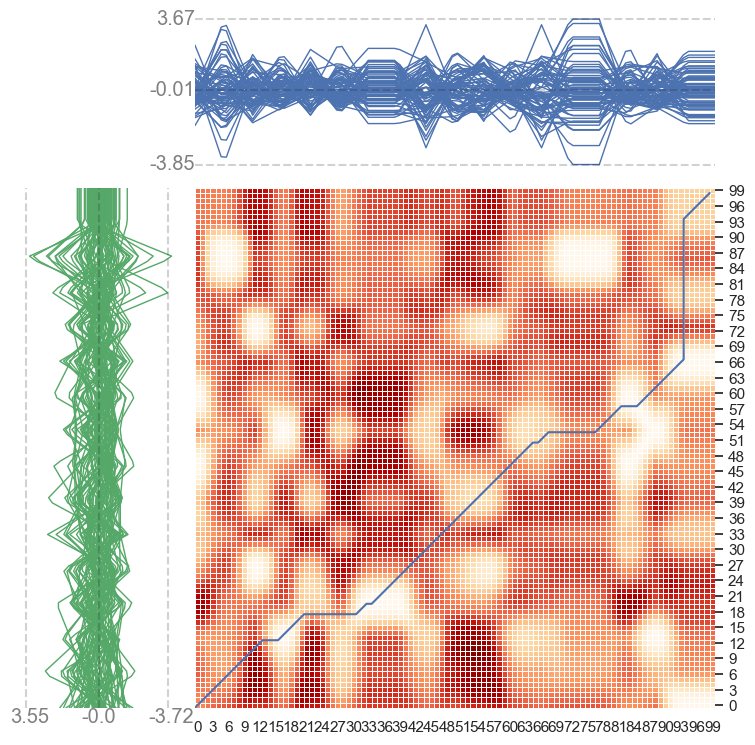

In [240]:
plot_matrices(x,y,dist_mat, annot=False, marker=None)

## Just another example

In [241]:
pep1_index = peptide_df[peptide_df.peptide =='AGKYVPAIAHLIHSLNPV'].index[0] # core start from 4 or 5
pep2_index = peptide_df[peptide_df.peptide =='VPLQPKHFRILNPVIIKE'].index[0] # core should start from  9


peptide1 = converted_peptides[pep1_index].T
peptide2 = converted_peptides[pep2_index].T

In [242]:

x_seq = peptide1.T
y_seq = peptide2.T

dist_mat = dist.cdist(x_seq, y_seq, "cosine")
path, cost_mat = dp(dist_mat)
print("Alignment cost: {:.4f}".format(cost_mat[-1, -1]))



Alignment cost: 13.9507


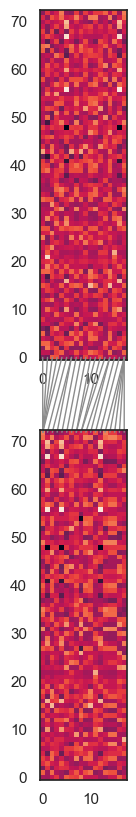

In [243]:
fig = plt.figure(figsize=(9, 10))
ax1 = fig.add_subplot(211)
ax2 = fig.add_subplot(212)

ax1.imshow(peptide1,  origin="lower", interpolation="nearest" )
ax2.imshow(peptide2, origin="lower", interpolation="nearest")


for x_i, y_j in path:
    con = ConnectionPatch(
        xyA=(x_i, 0), xyB=(y_j, peptide2.shape[0]-1), coordsA="data", coordsB="data",
        axesA=ax1, axesB=ax2, color="C7"
        )
    ax2.add_artist(con)

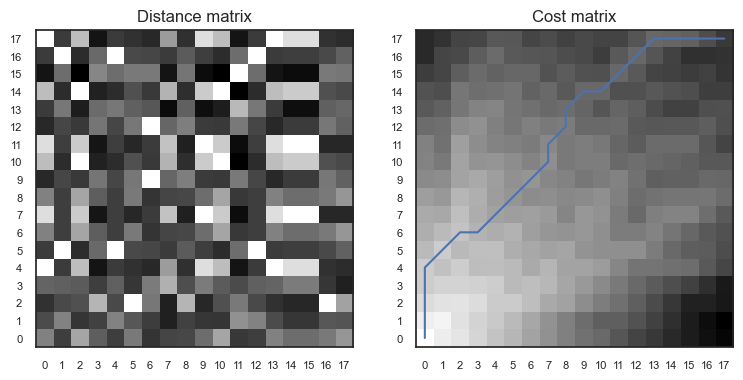

In [244]:

plt.figure(figsize=(9, 5))
plt.subplot(121)
plt.title("Distance matrix")
plt.imshow(dist_mat, cmap=plt.cm.binary, interpolation="nearest", origin="lower")
ax = plt.gca()
ax = plt.gca()
ax.set_xticks(np.arange(0, dist_mat.shape[1]))
ax.set_yticks(np.arange(0, dist_mat.shape[0]))
ax.tick_params(axis='both', labelsize=8)
ax.tick_params(axis='both', labelsize=8)
plt.subplot(122)
plt.title("Cost matrix")
plt.imshow(cost_mat, cmap=plt.cm.binary, interpolation="nearest", origin="lower")
ax = plt.gca()
ax.set_xticks(np.arange(0, cost_mat.shape[1]))
ax.set_yticks(np.arange(0, cost_mat.shape[0]))
ax.tick_params(axis='both', labelsize=8)
ax.tick_params(axis='both', labelsize=8)
x_path, y_path = zip(*path)
plt.plot(y_path, x_path);

# just another example

In [264]:

pep1_index = peptide_df[peptide_df.peptide =='AGKYVPAIAHLIHSLNPV'].index[0] # core start from 4 or 5
pep2_index = peptide_df[peptide_df.peptide =='VPLQPKHFRILNPVIIKE'].index[0] # core should start from  9
peptide1 = converted_peptides[pep1_index].T
peptide2 = converted_peptides[pep2_index].T

x = peptide1.T
y = peptide2.T

In [265]:
dist_mat = dist.cdist(x, y, "euclidean")
path, cost_mat = dp(dist_mat)
print("Alignment cost: {:.4f}".format(cost_mat[-1, -1]))

Alignment cost: 148.9356


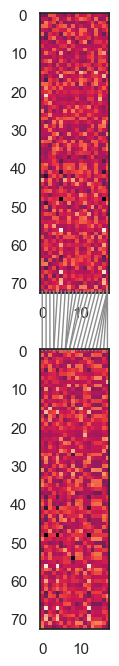

In [266]:
fig = plt.figure(figsize=(16,8))
ax1 = fig.add_subplot(211)
ax2 = fig.add_subplot(212)

ax1.imshow(x.T )
ax2.imshow(y.T)


for x_i, y_j in path:
    con = ConnectionPatch(
        xyA=(x_i, y.T.shape[0]-1), xyB=(y_j, 0), coordsA="data", coordsB="data",
        axesA=ax1, axesB=ax2, color="C7"
        )
    ax2.add_artist(con)

C:\Users\denkl\AppData\Local\Temp\ipykernel_23852\72974500.py:68: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


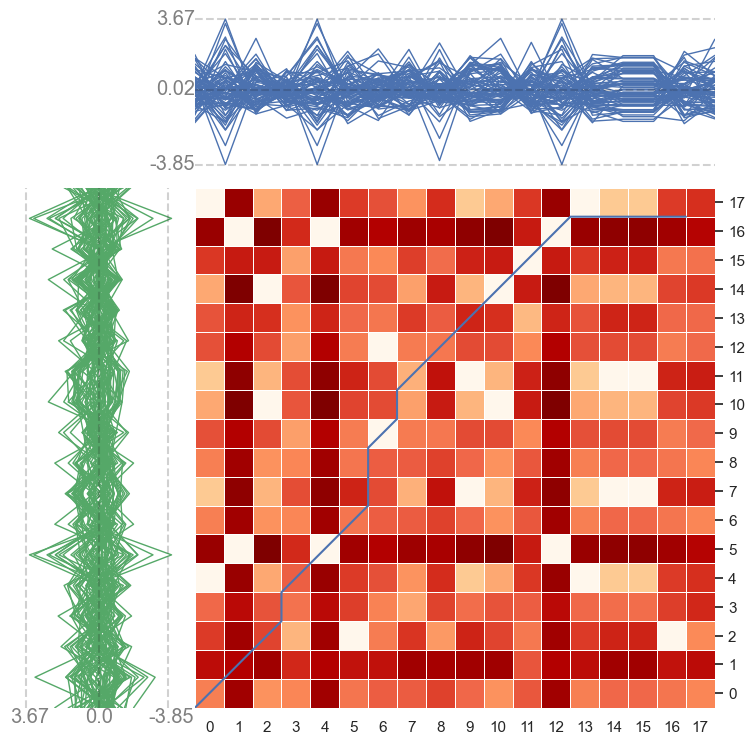

In [267]:
plot_matrices(x,y,dist_mat, annot=False, marker=None)

C:\Users\denkl\AppData\Local\Temp\ipykernel_23852\72974500.py:68: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


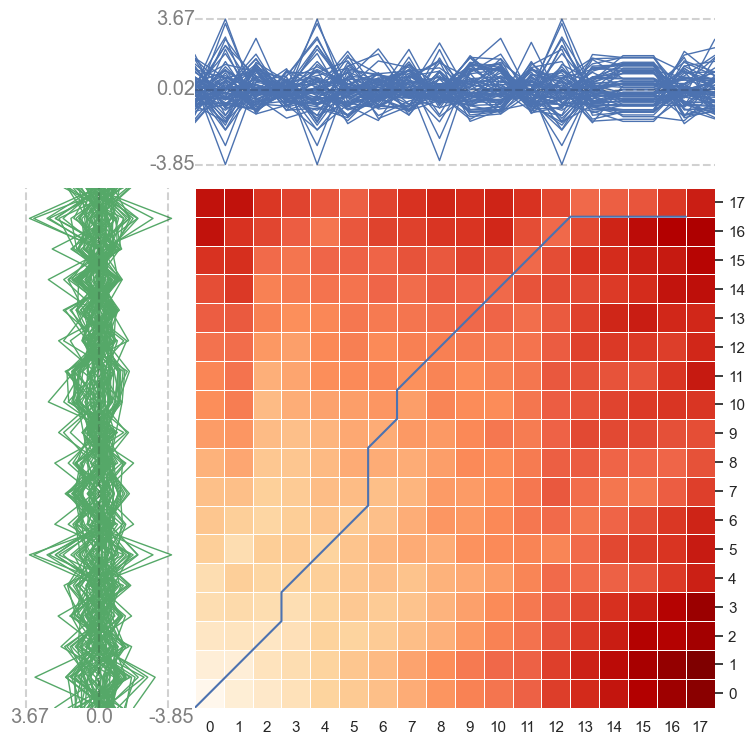

In [268]:
plot_matrices(x,y,cost_mat, annot=False, marker=None)

## another example with interpolation

In [273]:

pep1_index = peptide_df[peptide_df.peptide =='AGKYVPAIAHLIHSLNPV'].index[0] # core start from 4 or 5
pep2_index = peptide_df[peptide_df.peptide =='VPLQPKHFRILNPVIIKE'].index[0] # core should start from  9


peptide1 = converted_peptides[pep1_index].T
peptide2 = converted_peptides[pep2_index].T

x = peptide1.T
y = peptide2.T
x = interpolate_peptide(x)
y = interpolate_peptide(y)

In [294]:
dist_mat = dist.cdist(x, y, "cosine")
path, cost_mat = dp(dist_mat)
print("Alignment cost: {:.4f}".format(cost_mat[-1, -1]))

Alignment cost: 79.1110


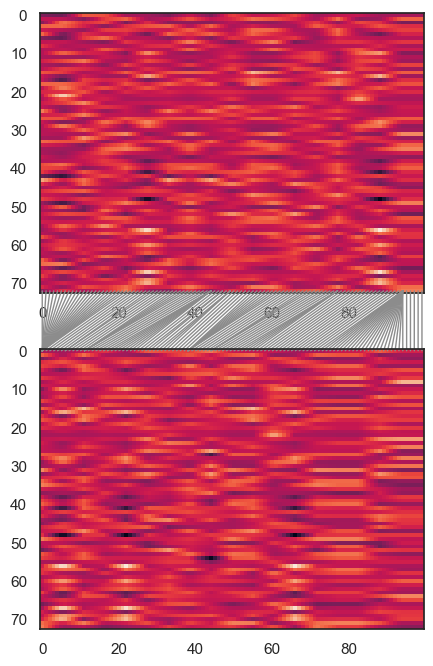

In [295]:
fig = plt.figure(figsize=(16,8))
ax1 = fig.add_subplot(211)
ax2 = fig.add_subplot(212)

ax1.imshow(x.T )
ax2.imshow(y.T)


for x_i, y_j in path:
    con = ConnectionPatch(
        xyA=(x_i, y.T.shape[0]-1), xyB=(y_j, 0), coordsA="data", coordsB="data",
        axesA=ax1, axesB=ax2, color="C7"
        )
    ax2.add_artist(con)

C:\Users\denkl\AppData\Local\Temp\ipykernel_23852\72974500.py:68: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


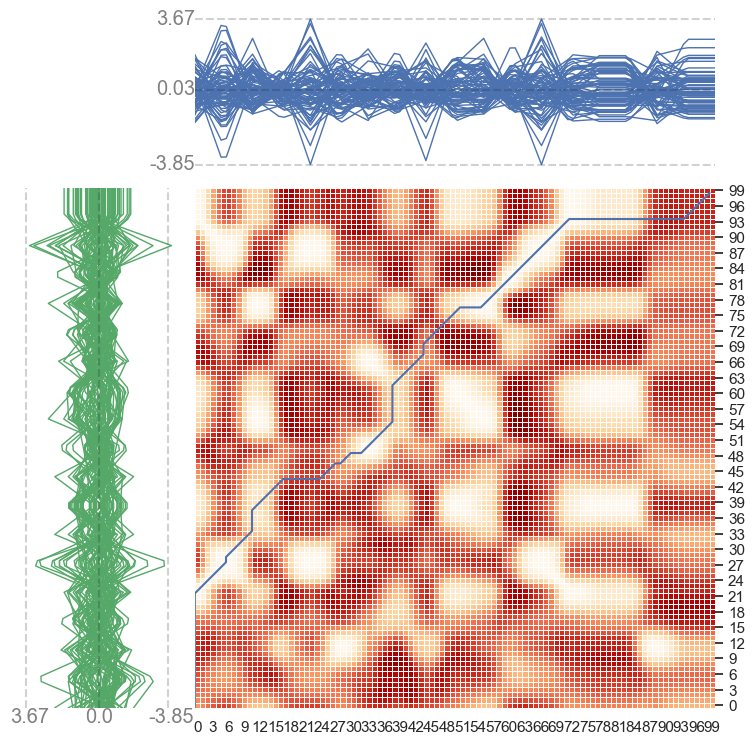

In [296]:
plot_matrices(x,y,dist_mat, annot=False, marker=None)

## Sliding window

In [306]:
s_x = x[0:10, :]
s_y =  y[0:10, :]

In [307]:
s_x.shape

(10, 73)

In [308]:
 dist.cdist(s_x, s_y, "euclidean").shape

(10, 10)

In [309]:
np.trace(dist.cdist(s_x, s_y, "euclidean"))

96.78039004676816

In [320]:
# Distance matrix
N = x.shape[0]
M = y.shape[0]
window_size = 11
dist_mat = np.zeros((N, M))
for i in range(N):
    for j in range(M):
            s_x = np.zeros((window_size, x.shape[1]))
            s_y = np.zeros((window_size, y.shape[1]))
            half_size = int(window_size/2)
            s_x[half_size + 1,:] = x[i, :]
            s_y[half_size + 1, :] = y[j, :]
            for k in range(half_size):
                s_x[k, :] = x[i - half_size + k -1, :] if i >=  k+1 else 0
                s_x[half_size + k, :] = x[i + k, :] if i <=   N-(k+1) else 0
                
                s_y[k, :] = y[j - half_size + k -1, :] if j >=  k+1 else 0
                s_y[half_size + k, :] = y[j + k, :] if j <=   M-(k+1) else 0
  
            
            dist_mat[i, j] = np.trace(dist.cdist(s_x, s_y, "chebyshev"))
            # dist_mat[i,j] = abs(x[i] - y[j])
            #dist_mat[i,j] = abs(x[i] - y[j])

In [321]:
path, cost_mat = dp(dist_mat)
print("Alignment cost: {:.4f}".format(cost_mat[-1, -1]))

Alignment cost: 2139.9867


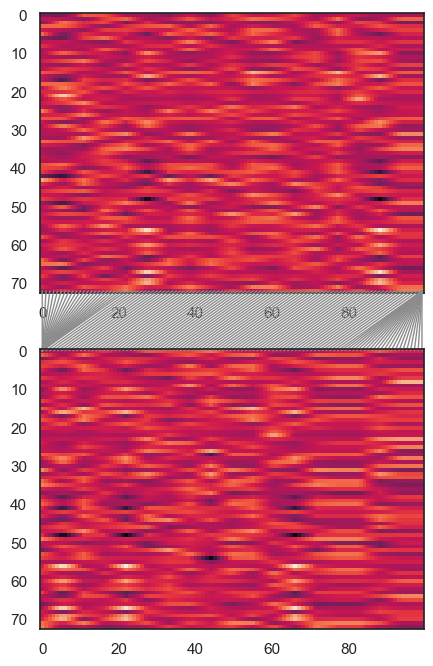

In [322]:
fig = plt.figure(figsize=(16,8))
ax1 = fig.add_subplot(211)
ax2 = fig.add_subplot(212)

ax1.imshow(x.T )
ax2.imshow(y.T)


for x_i, y_j in path:
    con = ConnectionPatch(
        xyA=(x_i, y.T.shape[0]-1), xyB=(y_j, 0), coordsA="data", coordsB="data",
        axesA=ax1, axesB=ax2, color="C7"
        )
    ax2.add_artist(con)

C:\Users\denkl\AppData\Local\Temp\ipykernel_23852\72974500.py:68: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


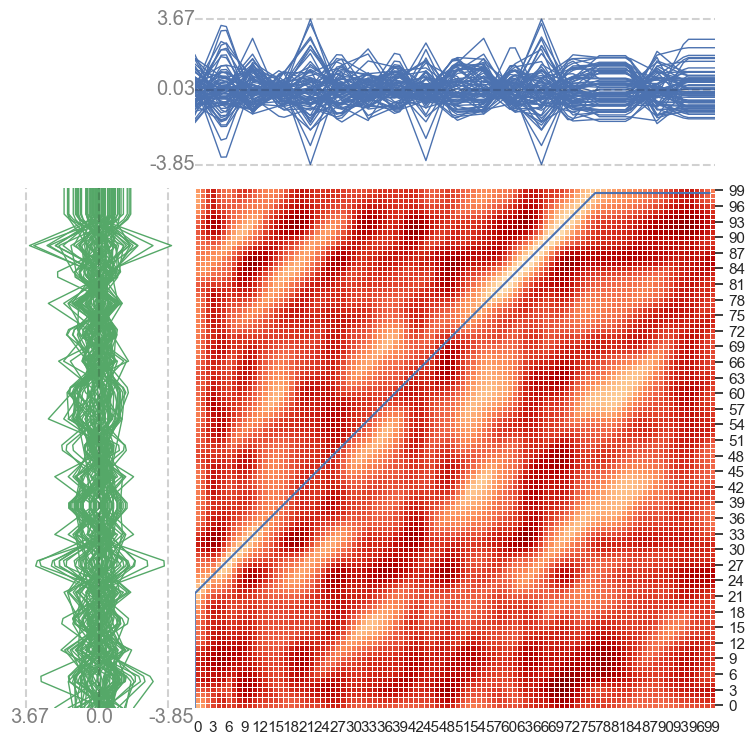

In [323]:
plot_matrices(x,y,dist_mat, annot=False, marker=None)

C:\Users\denkl\AppData\Local\Temp\ipykernel_23852\72974500.py:68: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


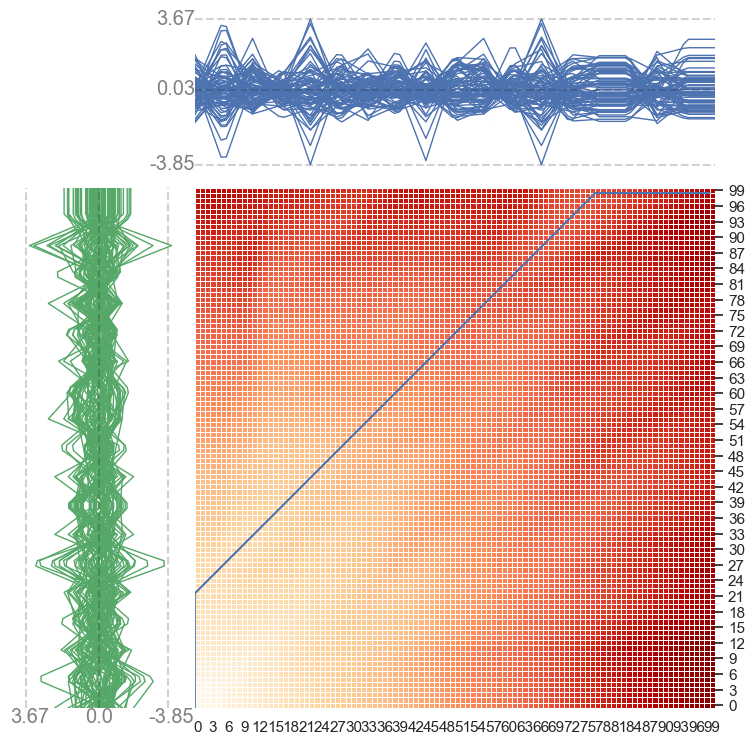

In [324]:
plot_matrices(x,y,cost_mat, annot=False, marker=None)

# Using library

In [1031]:
from tslearn.metrics import dtw, dtw_path

In [1045]:
pep1_index = peptide_df[peptide_df.peptide =='AGKYVPAIAHLIHSLNPV'].index[0] # core start from 4 or 5
pep2_index = peptide_df[peptide_df.peptide =='VPLQPKHFRILNPVIIKE'].index[0] # core should start from  9


# pep1_index = peptide_df[peptide_df.peptide =='KDSYVELASAKVRPQ'].index[0] # core start from 4 or 5
# pep2_index = peptide_df[peptide_df.peptide =='APVSFNYYGMITGPPASK'].index[0] # core start from  8


peptide1 = converted_peptides[pep1_index][:,4]
peptide2 = converted_peptides[pep2_index][:,4]


x = peptide1.reshape(-1,1)
y = peptide2.reshape(-1,1)




In [1046]:
x.shape

(18, 1)

In [1047]:
dtw_score = dtw(x, y)

In [1048]:
# Or, if the path is also an important information:
optimal_path, dtw_score = dtw_path(x, y)

In [1049]:
from tslearn.metrics import dtw_path_from_metric


In [1050]:
from scipy.spatial.distance import cdist
import matplotlib.pyplot as plt
from tslearn import metrics

def plot_dtw(x,y, path):
    sz_x = x.shape[0]
    sz_y = y.shape[0]
    plt.figure(1, figsize=(8, 8))
    # definitions for the axes
    left, bottom = 0.01, 0.1
    w_ts = h_ts = 0.2
    left_h = left + w_ts + 0.02
    width = height = 0.65
    bottom_h = bottom + height + 0.02

    rect_s_y = [left, bottom, w_ts, height]
    rect_gram = [left_h, bottom, width, height]
    rect_s_x = [left_h, bottom_h, width, h_ts]

    ax_gram = plt.axes(rect_gram)
    ax_s_x = plt.axes(rect_s_x)
    ax_s_y = plt.axes(rect_s_y)

    mat = cdist(x, y)

    ax_gram.imshow(mat, origin='lower')
    ax_gram.axis("off")
    ax_gram.autoscale(False)
    ax_gram.plot([j for (i, j) in path], [i for (i, j) in path], "w-",
                 linewidth=3.)
    ax_gram.tick_params(left=False, labelleft=False, right=True, labelright=True,rotation=0)

    ax_s_x.plot(np.arange(sz_y), y, "b-", linewidth=1.)
   # ax_s_x.axis("off")

    ax_s_x.set_xlim((0, sz_y - 1))
    ticks_location_x = [np.min(y), np.mean(y), np.max(y)]
    ticks_labels_x = [str(round(loc, 2)) for loc in ticks_location_x]
    # ticks_labels = [r"$\bf -v $", r"$\bf0$", r"$\bf v$"]
    ax_s_x.plot([0, sz_y - 1], [ticks_location_x]*2, "k--", alpha=.2)
    
    indexes_location_x = np.arange(sz_y)


    
    ax_s_y.plot(x, np.arange(sz_x), "g-", linewidth=1.)
   # ax_s_y.axis("off")
    ax_s_y.set_ylim((0, sz_x - 1))
    ticks_location_y = [np.min(x), np.mean(x), np.max(x)]
    ticks_labels_y = [str(round(loc, 2)) for loc in ticks_location_y]
    ax_s_y.plot([ticks_location_y]*2, [0, sz_x - 1], "k--", alpha=.2)


    for loc, s in zip(ticks_location_x, ticks_labels_x):
        ax_s_x.text(0, loc, s, fontsize="large", color="grey",
                    horizontalalignment="right", verticalalignment="center")

   
    

    for loc, s in zip(ticks_location_y, ticks_labels_y):
        ax_s_y.text(-loc, 0, s, fontsize="large", color="grey",
                    horizontalalignment="center", verticalalignment="top")
    

    
    


    plt.tight_layout()
    plt.show()

C:\Users\denkl\AppData\Local\Temp\ipykernel_14952\565114623.py:70: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


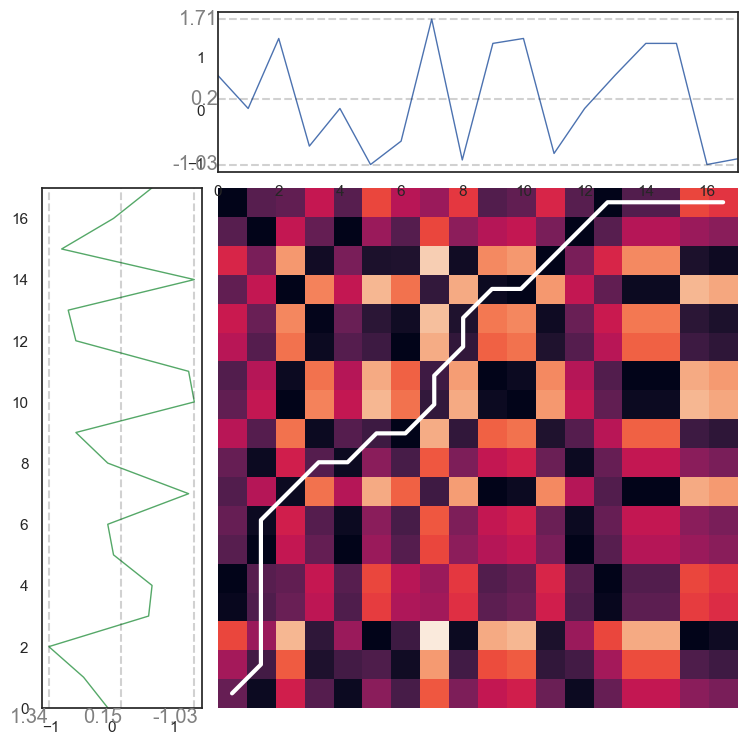

In [1055]:
path, cost = dtw_path_from_metric(x, y, metric='euclidean')
plot_dtw(x,y,path)

C:\Users\denkl\AppData\Local\Temp\ipykernel_14952\565114623.py:70: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


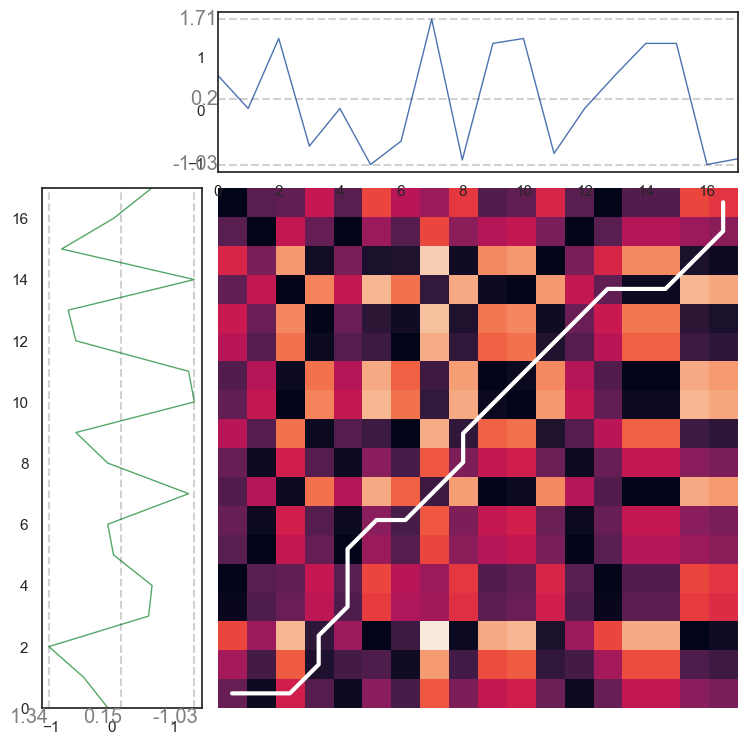

In [1056]:
from tslearn.metrics import dtw
path, cost = dtw_path_from_metric(x, y, global_constraint="sakoe_chiba", sakoe_chiba_radius=3)
plot_dtw(x,y,path)

C:\Users\denkl\AppData\Local\Temp\ipykernel_14952\565114623.py:70: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


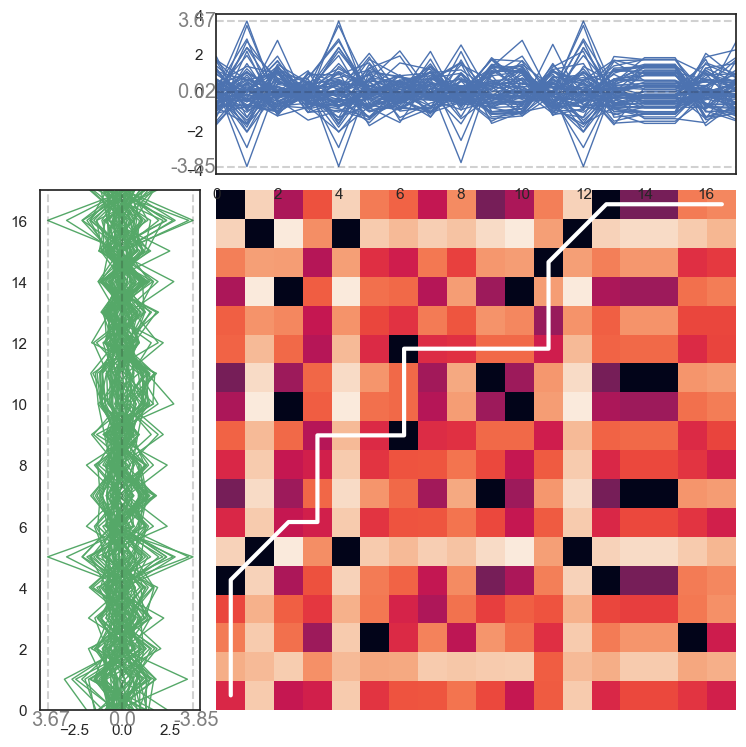

In [950]:
from tslearn.metrics import soft_dtw
path, cost = dtw_path_from_metric(x, y, metric=soft_dtw)
plot_dtw(x,y,path)

C:\Users\denkl\AppData\Local\Temp\ipykernel_14952\565114623.py:70: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


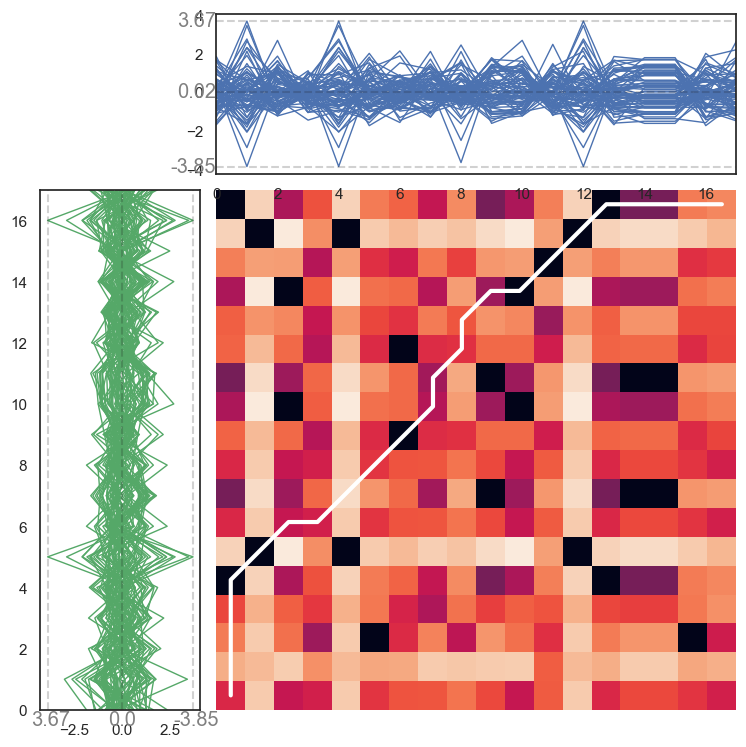

In [951]:
from tslearn.metrics import soft_dtw
path, cost = dtw_path_from_metric(x, y, metric='cosine')
plot_dtw(x,y,path)

C:\Users\denkl\AppData\Local\Temp\ipykernel_14952\565114623.py:70: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


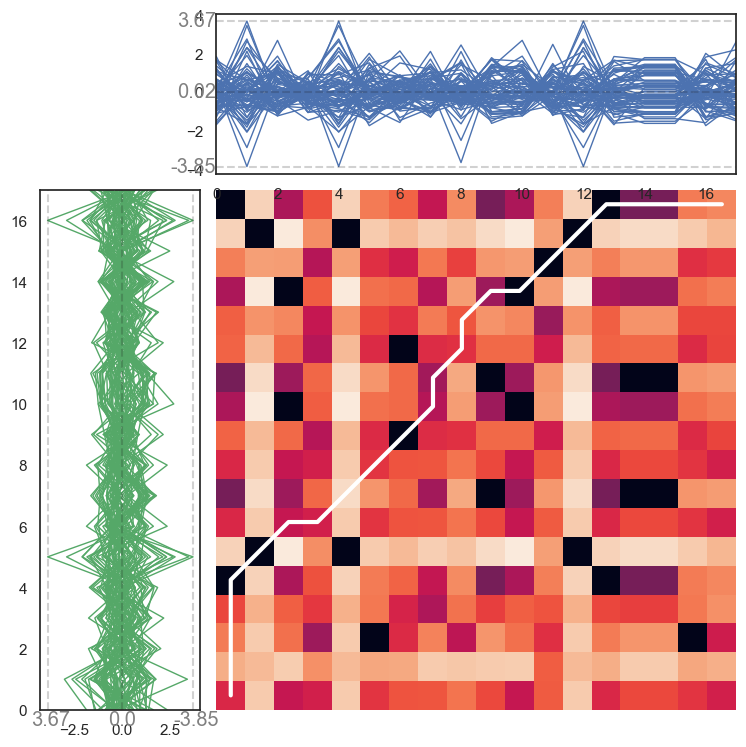

In [952]:
from tslearn.metrics import soft_dtw
path, cost = dtw_path_from_metric(x, y, metric='correlation')
plot_dtw(x,y,path)

# Scale first

In [953]:
peptide_df = pd.concat(dfs)

peptide_df = peptide_df[peptide_df['length'].isin([16])]
peptide_df = peptide_df[peptide_df['split'].isin([0])]
peptide_df = peptide_df.reset_index(drop=True)

list_peptides = [list(peptide) for peptide in peptide_df.peptide.values]
converted_peptides = [np.array([[transform_dict[aa] for transform_dict in transform_dicts] for aa in  peptide]) for peptide in list_peptides]
converted_peptides = np.array(converted_peptides)

In [954]:
converted_peptides.shape

(1433, 16, 73)

In [955]:
from tslearn.preprocessing import TimeSeriesScalerMeanVariance

In [956]:
converted_peptides = TimeSeriesScalerMeanVariance(mu=0.,  std=1.).fit_transform(converted_peptides)

In [957]:
pep1_index = peptide_df[peptide_df.peptide =='VDLIPKFLMANGQLVK'].index[0] # core start from 7
pep2_index = peptide_df[peptide_df.peptide =='NNYQAQSAVPLRHETH'].index[0] # core should start from  3

peptide1 = converted_peptides[pep1_index]
peptide2 = converted_peptides[pep2_index]


x = peptide1
y = peptide2

In [958]:
peptide1.shape

(16, 73)

C:\Users\denkl\AppData\Local\Temp\ipykernel_14952\565114623.py:70: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


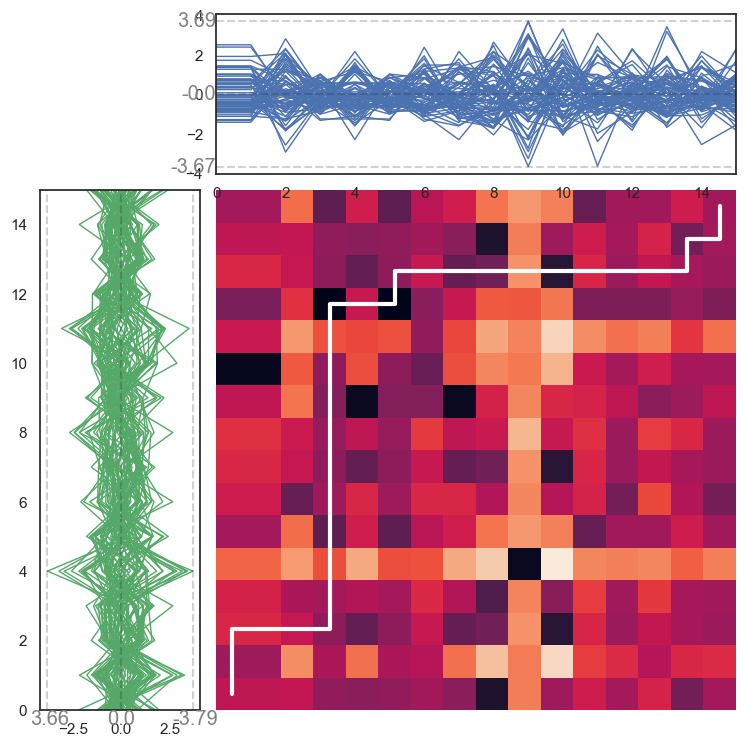

In [959]:
path, cost = dtw_path_from_metric(x, y, metric=soft_dtw)
plot_dtw(x,y,path)

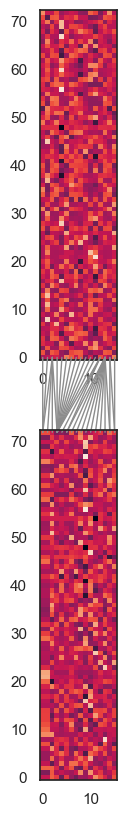

In [960]:
fig = plt.figure(figsize=(9, 10))
ax1 = fig.add_subplot(211)
ax2 = fig.add_subplot(212)

ax1.imshow(peptide1.T,  origin="lower", interpolation="nearest" )
ax2.imshow(peptide2.T, origin="lower", interpolation="nearest")


for x_i, y_j in path:
    con = ConnectionPatch(
        xyA=(x_i, 0), xyB=(y_j, peptide2.T.shape[0]-1), coordsA="data", coordsB="data",
        axesA=ax1, axesB=ax2, color="C7"
        )
    ax2.add_artist(con)

In [961]:
pep1_index = peptide_df[peptide_df.peptide =='DAFALARAQLLDYKVA'].index[0] # core start from 3
pep2_index = peptide_df[peptide_df.peptide =='DREDDQYSHLQGNQLR'].index[0] # core should start from  7

peptide1 = converted_peptides[pep1_index][:, 50:70]
peptide2 = converted_peptides[pep2_index][:, 50:70]


x = peptide1
y = peptide2

C:\Users\denkl\AppData\Local\Temp\ipykernel_14952\565114623.py:70: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


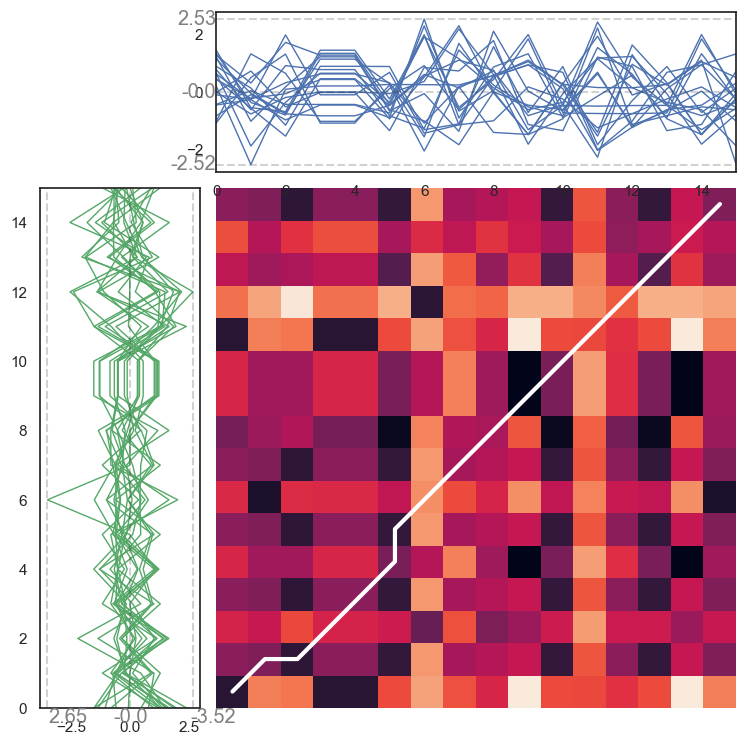

In [962]:
path, cost = dtw_path_from_metric(x, y, metric='cosine')
plot_dtw(x,y,path)

C:\Users\denkl\AppData\Local\Temp\ipykernel_14952\565114623.py:70: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


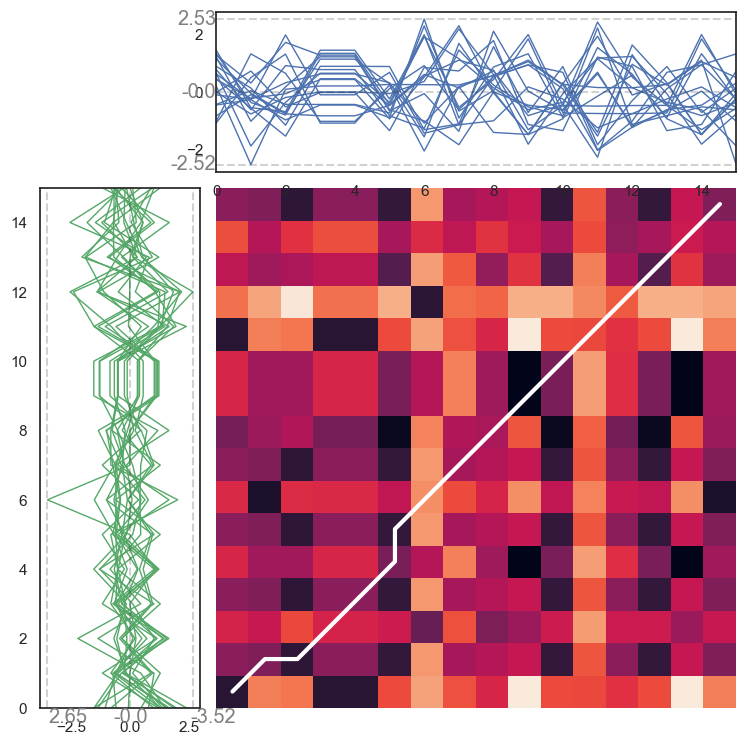

In [963]:
path, cost = dtw_path_from_metric(x, y, metric='correlation')
plot_dtw(x,y,path)

## Clustering?
now we can somehow determine similarity between two time series (peptides)
let's try to cluster them

In [787]:
peptide_df = pd.concat(dfs)

peptide_df = peptide_df[peptide_df['length'].isin([15])]
peptide_df = peptide_df[peptide_df['split'].isin([0])]
peptide_df = peptide_df.reset_index(drop=True)

list_peptides = [list(peptide) for peptide in peptide_df.peptide.values]
converted_peptides = [np.array([[transform_dict[aa] for transform_dict in transform_dicts] for aa in  peptide]) for peptide in list_peptides]
converted_peptides = np.array(converted_peptides)

In [788]:
import numpy
import matplotlib.pyplot as plt

from tslearn.clustering import TimeSeriesKMeans
from tslearn.datasets import CachedDatasets
from tslearn.preprocessing import TimeSeriesScalerMeanVariance, \
    TimeSeriesResampler


In [789]:
km = TimeSeriesKMeans(n_clusters=6, verbose=True, random_state=2)
y_pred = km.fit_predict(converted_peptides)

1352.005 --> 777.162 --> 770.032 --> 767.242 --> 765.905 --> 765.259 --> 764.807 --> 764.429 --> 764.164 --> 763.972 --> 763.811 --> 763.712 --> 763.659 --> 763.616 --> 763.562 --> 763.499 --> 763.445 --> 763.402 --> 763.358 --> 763.327 --> 

KeyboardInterrupt: 

Euclidean k-means
1355.342 --> 788.021 --> 783.638 --> 781.914 --> 780.478 --> 779.008 --> 777.910 --> 777.283 --> 776.940 --> 776.762 --> 776.652 --> 776.563 --> 776.490 --> 776.417 --> 776.337 --> 776.251 --> 776.188 --> 776.124 --> 776.051 --> 775.979 --> 775.888 --> 775.771 --> 775.679 --> 775.576 --> 775.480 --> 775.384 --> 775.332 --> 775.306 --> 775.284 --> 775.266 --> 775.252 --> 775.241 --> 775.236 --> 775.234 --> 775.234 --> 775.233 --> 775.233 --> 775.233 --> 
DBA k-means
Soft-DTW k-means
1214556.142 --> 497557.631 --> 482474.350 --> 476211.854 --> 474351.623 --> 473564.190 --> 472956.903 --> 472424.428 --> 458355.020 --> 448760.166 --> 448371.527 --> 448162.244 --> 447817.385 --> 447746.749 --> 447717.410 --> 447675.334 --> 447656.881 --> 447651.715 --> 447647.175 --> 447647.497 --> 447646.322 --> 447645.641 --> 447645.526 --> 447645.614 --> 447645.608 --> 447645.613 --> 447645.610 --> 447645.611 --> 447645.611 --> 447645.611 --> 


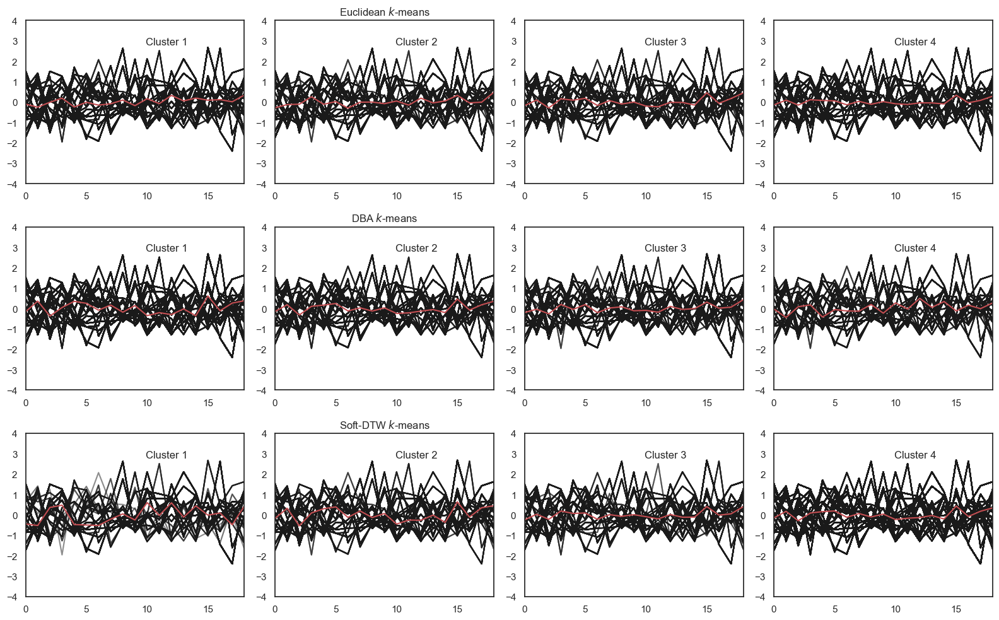

In [316]:
n_clusters = 4
# Euclidean k-means
print("Euclidean k-means")

km = TimeSeriesKMeans(n_clusters=n_clusters, verbose=True, random_state=3)
y_pred = km.fit_predict(converted_peptides)
y_pred_km = y_pred

plt.figure(figsize=(16,10))
for yi in range(n_clusters):
    plt.subplot(3, n_clusters, yi + 1)
    for xx in converted_peptides[y_pred == yi]:
        plt.plot(xx.ravel(), "k-", alpha=.2)
    plt.plot(km.cluster_centers_[yi].ravel(), "r-")
    plt.xlim(0, sz)
    plt.ylim(-4, 4)
    plt.text(0.55, 0.85,'Cluster %d' % (yi + 1),
             transform=plt.gca().transAxes)
    if yi == 1:
        
        plt.title("Euclidean $k$-means")
# DBA-k-means
print("DBA k-means")
dba_km = TimeSeriesKMeans(n_clusters=n_clusters,
                          n_init=2,
                          metric="dtw",
                          verbose=False,
                          max_iter_barycenter=10,
                          random_state=3)
y_pred = dba_km.fit_predict(converted_peptides)
y_pred_dba=y_pred
for yi in range(n_clusters):
    plt.subplot(3, n_clusters, n_clusters+1 + yi)
    for xx in converted_peptides[y_pred == yi]:
        plt.plot(xx.ravel(), "k-", alpha=.2)
    plt.plot(dba_km.cluster_centers_[yi].ravel(), "r-")
    plt.xlim(0, sz)
    plt.ylim(-4, 4)
    plt.text(0.55, 0.85,'Cluster %d' % (yi + 1),
             transform=plt.gca().transAxes)
    if yi == 1:
        plt.title("DBA $k$-means")
        
# Soft-DTW-k-means
print("Soft-DTW k-means")
sdtw_km = TimeSeriesKMeans(n_clusters=n_clusters,
                           metric="softdtw",
                           metric_params={"gamma": .01},
                           verbose=True,
                           random_state=3)
y_pred = sdtw_km.fit_predict(converted_peptides)
y_pred_softdtw=y_pred
for yi in range(n_clusters):
    plt.subplot(3, n_clusters, n_clusters*2+1 + yi)
    for xx in converted_peptides[y_pred == yi]:
        plt.plot(xx.ravel(), "k-", alpha=.2)
    plt.plot(sdtw_km.cluster_centers_[yi].ravel(), "r-")
    plt.xlim(0, sz)
    plt.ylim(-4, 4)
    plt.text(0.55, 0.85,'Cluster %d' % (yi + 1),
             transform=plt.gca().transAxes)
    if yi == 1:
        plt.title("Soft-DTW $k$-means")

plt.tight_layout()
plt.show()

0
1
2
3


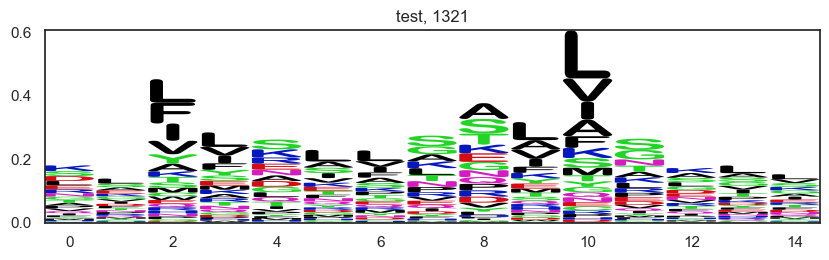

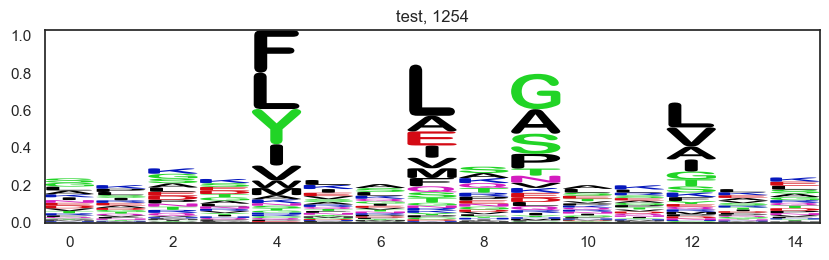

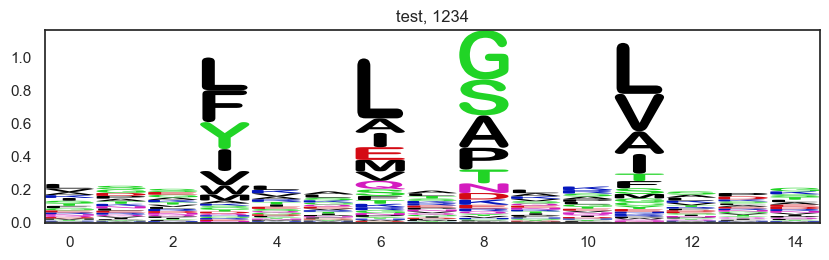

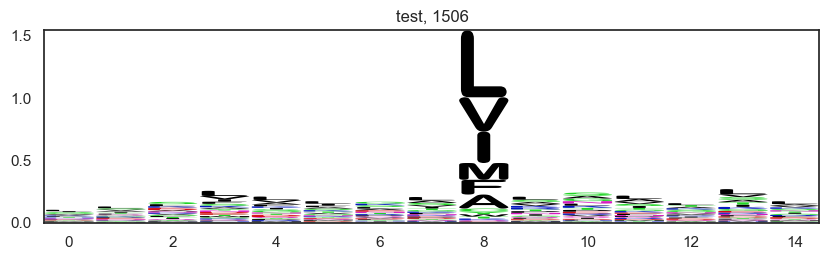

In [329]:
for cluster_num in range(n_clusters):
    print(cluster_num)
    temp_df =  peptide_df.loc[y_pred_km == cluster_num]
  #  temp_df.to_csv(f"test/cluster{cluster_num}.csv", sep=";", index=False)
    make_logo_for_data(temp_df.peptide.values, name="test")

0
1
2
3


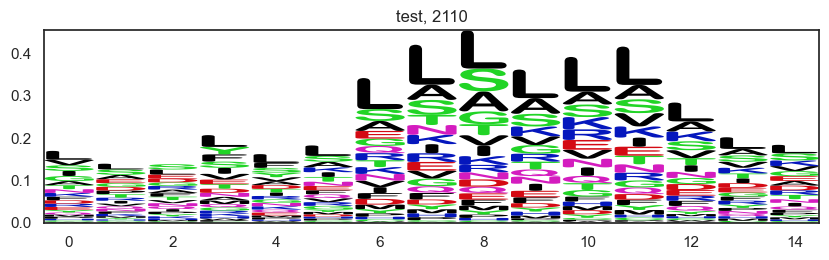

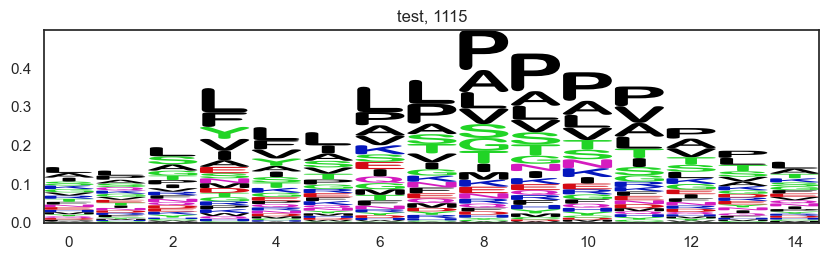

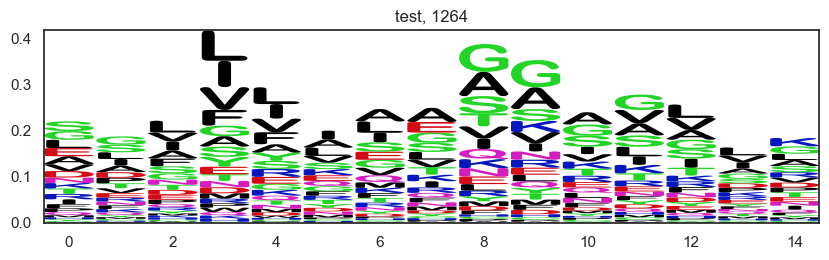

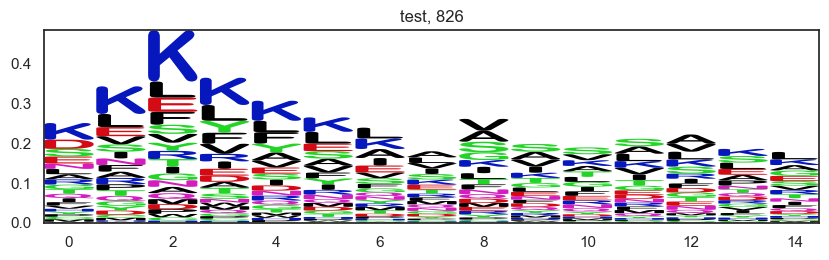

In [318]:
for cluster_num in range(n_clusters):
    print(cluster_num)
    temp_df =  peptide_df.loc[y_pred_dba == cluster_num]
    temp_df.to_csv(f"test/cluster{cluster_num}.csv", sep=";", index=False)
    make_logo_for_data(temp_df.peptide.values, name="test")

0
1
2
3


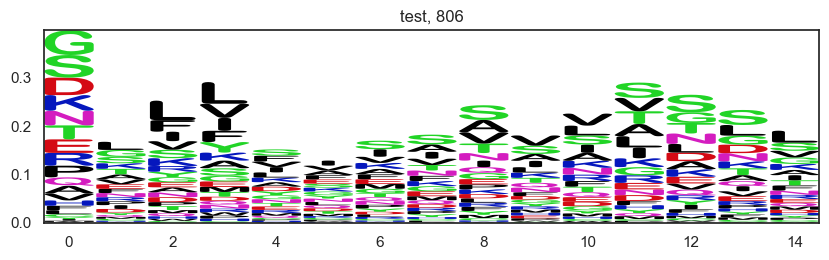

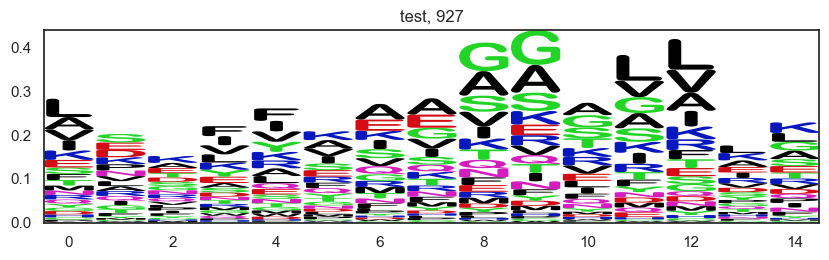

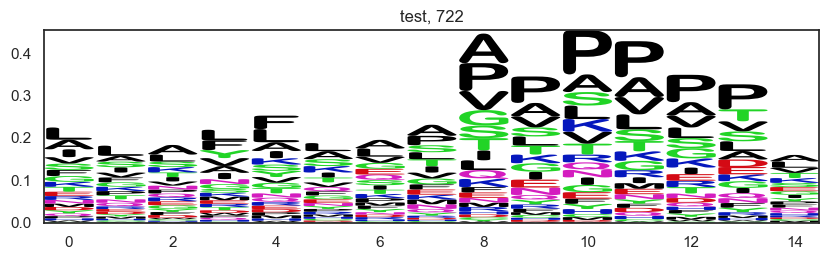

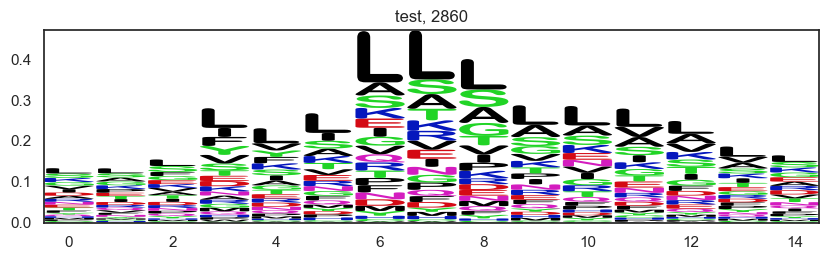

In [330]:
for cluster_num in range(n_clusters):
    print(cluster_num)
    temp_df =  peptide_df.loc[y_pred_softdtw == cluster_num]
  #  temp_df.to_csv(f"test/cluster{cluster_num}.csv", sep=";", index=False)
    make_logo_for_data(temp_df.peptide.values, name="test")

In [309]:
for cluster_num in range(n_clusters):
    print(cluster_num)
    temp_df =  peptide_df.loc[y_pred_dba == cluster_num]
    temp_df.to_csv(f"test/cluster{cluster_num}.csv", sep=";", index=False)
    #make_logo_for_data(temp_df.peptide.values, name="test")

0
1
2
3
4
5
6
7
8
9


In [319]:
df = pd.read_csv("test/cluster0.csv", sep=";")

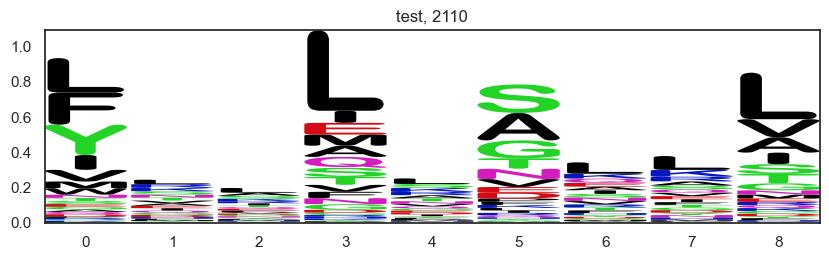

In [320]:
make_logo_for_data(df.cores.values, name="test")

In [321]:
df = pd.read_csv("test/cluster1.csv", sep=";")

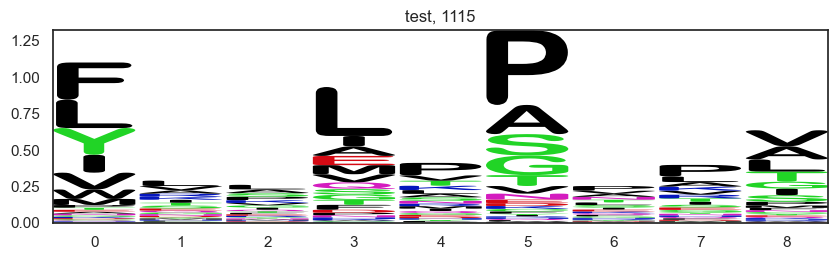

In [322]:
make_logo_for_data(df.cores.values, name="test")

In [323]:
df = pd.read_csv("test/cluster2.csv", sep=";")

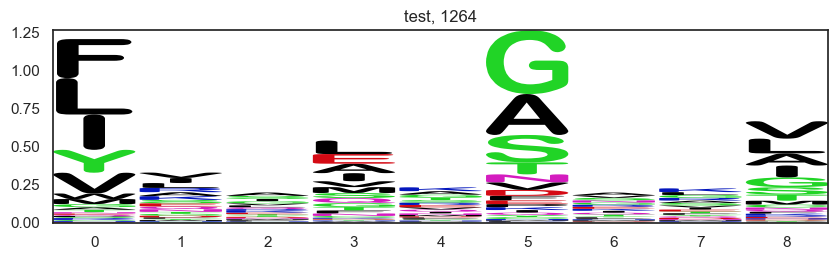

In [324]:
make_logo_for_data(df.cores.values, name="test")

In [325]:
df = pd.read_csv("test/cluster3.csv", sep=";")

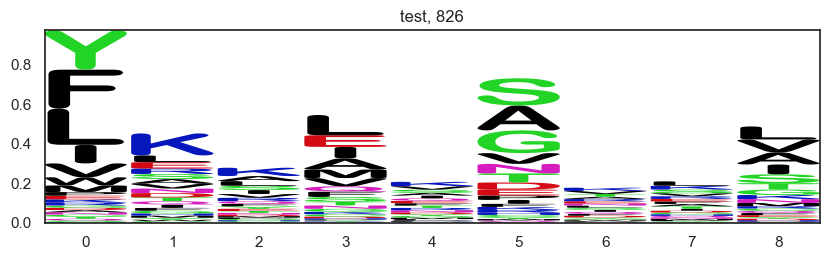

In [326]:
make_logo_for_data(df.cores.values, name="test")

In [240]:
from tslearn.clustering import TimeSeriesKMeans

In [241]:
km = TimeSeriesKMeans(n_clusters=5, metric="dtw")

In [242]:
from tslearn.generators import random_walks

X = random_walks(n_ts=50, sz=32, d=4)

In [243]:
X_L = list(X)

In [244]:
X.shape

(50, 32, 4)

In [245]:
km = TimeSeriesKMeans(n_clusters=3, metric="euclidean", max_iter=5,

                      random_state=0).fit(X_L)

In [246]:
km.cluster_centers_.shape

(3, 32, 4)

In [ ]:
result_distance_matrix = np.zeros((1000, 1000))


for pep1_index in range(len(converted_peptides[:1000])):
    print(pep1_index)
    for pep2_index in range(pep1_index+1 , len(converted_peptides[:1000])):
        peptide1 = converted_peptides[pep1_index].T
        peptide2 = converted_peptides[pep2_index].T
        N = peptide1.shape[1]
        M = peptide2.shape[1]
        dist_mat = dist.cdist(x_seq, y_seq, "cosine")
        path, cost_mat = dp(dist_mat)
        result_norm_distance = cost_mat[-1, -1]/(M + N)
        result_distance_matrix[pep1_index, pep2_index] = result_norm_distance
            
            





0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89
90
91
92
93
94
95
96
97
98
99
100
101
102
103
104
105
106
107
108
109
110
111
112
113
114
115
116
117
118
119
120
121
122
123
124
125
126
127
128
129
130
131
132
133
134
135
136
137
138
139
140
141
142
143
144
145
146
147
148
149
150
151
152
153
154
155
156
157
158
159
160
161
162
163
164
165
166
167
168
169
170
171
172
173
174
175
176
177
178
179
180
181
182
183
184
185
186
187
188
189
190
191
192
193
194
195
196
197
198
199
200
201
202
203
204
205
206
207
208
209
210
211
212
213
214
215
216
217
218
219
220
221
222
223
224
225
226
227
228
229
230
231
232
233
234
235
236
237
238
239


In [80]:
import random
centroids=random.sample(converted_peptides,3)

In [83]:
centroids[0].T.shape

(73, 15)

In [105]:

import random

def k_means_clust(data,num_clust,num_iter):
    centroids=random.sample(data,num_clust)
    counter=0
    for n in range(num_iter):
        counter+=1
        print(counter)
        assignments={}
        #assign data points to clusters
        for ind,i in enumerate(data):
            min_dist=float('inf')
            closest_clust=None
            pep1= i.T
            for c_ind,j in enumerate(centroids):
                pep2 = j.T
                N = pep1.shape[1]
                M = pep2.shape[1]
                dist_mat = dist.cdist(x_seq, y_seq, "cosine")
                path, cost_mat = dp(dist_mat)
                result_norm_distance = cost_mat[-1, -1]/(M + N)
                cur_dist=result_norm_distance
                if cur_dist<min_dist:
                    min_dist=cur_dist
                    closest_clust=c_ind
            if closest_clust in assignments:
                assignments[closest_clust].append(ind)
            else:
                assignments[closest_clust]=[]
    
        #recalculate centroids of clusters
        for key in assignments:
            clust_sum=0
            for k in assignments[key]:
                clust_sum=clust_sum+data[k]
            centroids[key]=np.array([m/len(assignments[key]) for m in clust_sum])
    
    return centroids, assignments
        



In [106]:
data = converted_peptides[:1000]

In [107]:
clust_sum=0
clust_sum=clust_sum+data[0]
clust_sum=clust_sum+data[1]
clust_sum=clust_sum+data[2]

In [108]:
centroids, assignments =  k_means_clust(data,6,10)

1
2
3
4
5
6
7
8
9
10


In [110]:
centroids, assignments = centroids

In [114]:
len(assignments[1])

KeyError: 1

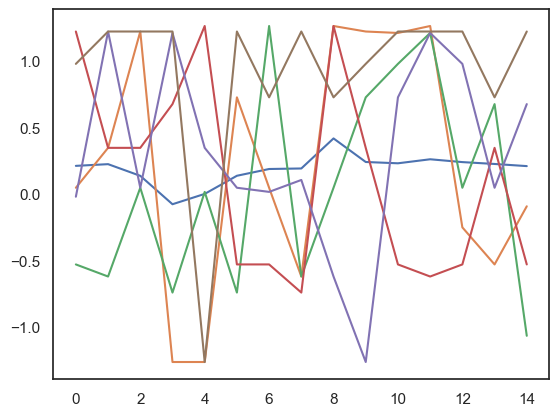

In [104]:

for i in centroids:
    
    plt.plot(i[:,sel_prop])

plt.show()

In [77]:
p.shape

(15, 73)

In [78]:
for i,p in enumerate(data):
    p.T
    break

In [87]:
centroids

[array([[ 0.46865839, -0.61031418,  0.05579314, ...,  0.73756136,
         -0.51644401, -1.45223782],
        [-0.11371426,  0.96379069, -1.13366492, ...,  0.32877723,
          1.68932723,  0.58146394],
        [-0.47846174, -1.06116846,  0.52595029, ...,  1.56586893,
         -1.9193591 , -0.25652562],
        ...,
        [-0.22987901,  1.35458229, -1.0919621 , ..., -1.23577894,
          1.5933336 , -0.38095781],
        [-0.11371426,  0.96379069, -1.13366492, ...,  0.32877723,
          1.68932723,  0.58146394],
        [ 1.10955271, -1.29067309,  0.32619957, ..., -0.40509272,
          0.92721703, -0.56218568]]),
 array([[-1.73299025, -0.32362486,  1.50540098, ...,  0.14173162,
         -1.0930353 ,  0.46309967],
        [-1.73299025, -0.32362486,  1.50540098, ...,  0.14173162,
         -1.0930353 ,  0.46309967],
        [ 1.53828102, -0.16215334,  0.25953423, ..., -0.40848768,
         -0.10972795,  0.09978108],
        ...,
        [-0.80604768, -0.86104049,  0.39520571, ...,  